# PRCP-1017 — Auto Price Prediction
## 1. Project Introduction

This notebook is the single deliverable for the **PRCP-1017 Auto Price Prediction** assignment. It covers data validation, exploratory analysis, preprocessing, feature engineering, regression modelling, hyperparameter tuning, model comparison, explainable AI, business recommendations and the challenges faced, all in one place.

The data is the **1985 Auto Imports Database** (Jeffrey C. Schlimmer, 1987): technical specifications of imported cars together with their insurance risk rating and normalised losses.

**Progress:** All phases are implemented: loading and validation, exploratory analysis, feature engineering, preprocessing, train-test split, model training, cross-validation, hyperparameter tuning, final evaluation, explainability, reporting and saving of the production model.

### Before running the notebook

Keep `auto_imports.csv` and `auto_imports_names.txt` either in `data/raw/` under the project folder or beside this notebook. Run **Kernel → Restart Kernel and Run All Cells** from top to bottom. The notebook creates its processed data, figures and model artifacts in the project folder.

## 2. Business Problem Statement

Dealers, insurers and importers need a defensible estimate of what a car should cost given its specification. Pricing by hand is slow and inconsistent. A model that predicts `price` from engine, body, size and efficiency attributes can support:

- fair listing and trade-in valuation,
- spotting vehicles priced out of line with their specification,
- understanding which attributes drive price.

## 3. Project Objectives

1. Load and validate the raw data without altering the original file.
2. Explore the data and relationships with `price`.
3. Treat missing values and encode features without data leakage.
4. Train and compare several regression algorithms (80:20 split, `random_state=42`, 5-fold CV).
5. Tune the most promising models, using **MAE** as the primary metric (RMSE and R² as supporting metrics).
6. Explain the final model and give business recommendations.
7. Save a production-ready pipeline.

## 4. Dataset Description

| Property | Value |
|---|---|
| Source | 1985 Ward's Automotive Yearbook, Insurance Services Office, Insurance Institute for Highway Safety |
| Documented instances | 205 |
| Instances in the supplied CSV | 201 (confirmed in Section 7; the 4 cars with no recorded price are absent) |
| Attributes | 26 (15 continuous, 1 integer, 10 nominal) |
| Target | `price` |
| Missing marker | `?` |
| Header row | none |

Key attributes:

- **`symboling`** is the insurance risk rating from -3 (safe) to +3 (risky).
- **`normalized-losses`** is the relative average loss payment per insured vehicle year, normalised within a size class.
- The remaining attributes are physical and mechanical specifications (dimensions, weight, engine, fuel, efficiency).

The supplied CSV has no header, so column names come from the documentation file `auto_imports_names.txt`.

## 5. Importing Libraries

Only the libraries needed for Phase 1 are imported here. Modelling libraries are added in the phases that use them. `RANDOM_STATE = 42` is fixed once so every later step is reproducible.

In [16]:
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

# Works whether the notebook is started from the project root or from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_CSV = PROJECT_ROOT / "data" / "raw" / "auto_imports.csv"
RAW_NAMES = PROJECT_ROOT / "data" / "raw" / "auto_imports_names.txt"

# Also support keeping the notebook and both input files together in one folder.
if not RAW_CSV.exists():
    RAW_CSV = PROJECT_ROOT / "auto_imports.csv"
if not RAW_NAMES.exists():
    RAW_NAMES = PROJECT_ROOT / "auto_imports_names.txt"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw CSV exists:  ", RAW_CSV.exists())
print("Names file exists:", RAW_NAMES.exists())

Project root: /content
Raw CSV exists:   True
Names file exists: False


## 6. Loading Dataset

The CSV has **no header row**, so it is read with `header=None`. Every column is read as text (`dtype=str`) so the `?` placeholders are preserved exactly and can be counted before anything is converted. Column names are then assigned in the documented order.

A SHA-256 fingerprint of the raw file is recorded now and re-checked in Section 8 to prove the original was never modified.

In [17]:
COLUMN_NAMES = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight", "engine-type",
    "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg",
    "price",
]
TARGET = "price"


def sha256_of(path: Path) -> str:
    """Return the SHA-256 hex digest of a file."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


def load_raw_dataset(path: Path, column_names: list) -> pd.DataFrame:
    """Read the header-less CSV as text and attach the documented column names."""
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path}")
    frame = pd.read_csv(path, header=None, dtype=str)
    if frame.shape[1] != len(column_names):
        raise ValueError(
            f"Expected {len(column_names)} columns but the file has {frame.shape[1]}."
        )
    frame.columns = column_names
    return frame


# Fallback to current directory if RAW_CSV path doesn't exist
actual_csv_path = RAW_CSV if RAW_CSV.exists() else Path.cwd() / "auto_imports.csv"

raw_hash_before = sha256_of(actual_csv_path)
df_raw = load_raw_dataset(actual_csv_path, COLUMN_NAMES)

print(f"Dataset dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"Raw file SHA-256:   {raw_hash_before[:16]}...")

Dataset dimensions: 201 rows x 26 columns
Raw file SHA-256:   bf76211fc32da0a9...


In [18]:
display(df_raw.head(5))
display(df_raw.tail(5))

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,171.20,65.50,52.40,2823,ohcv,six,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.80,176.60,66.20,54.30,2337,ohc,four,109,mpfi,3.19,3.40,10.00,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.40,176.60,66.40,54.30,2824,ohc,five,136,mpfi,3.19,3.40,8.00,115,5500,18,22,17450


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
196,-1,95,volvo,gas,std,four,sedan,rwd,front,109.10,188.80,68.90,55.50,2952,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,23,28,16845
197,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.10,188.80,68.80,55.50,3049,ohc,four,141,mpfi,3.78,3.15,8.70,160,5300,19,25,19045
198,-1,95,volvo,gas,std,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3012,ohcv,six,173,mpfi,3.58,2.87,8.80,134,5500,18,23,21485
199,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3217,ohc,six,145,idi,3.01,3.40,23.00,106,4800,26,27,22470
200,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.10,188.80,68.90,55.50,3062,ohc,four,141,mpfi,3.78,3.15,9.50,114,5400,19,25,22625


## 7. Data Validation

### 7.1 Structure checks

The project plan expects **201 rows and 26 columns** and `price` as the target. These are asserted, so the notebook stops loudly if the file is not what we think it is.

In [19]:
EXPECTED_ROWS, EXPECTED_COLS = 201, 26

assert df_raw.shape == (EXPECTED_ROWS, EXPECTED_COLS), f"Unexpected shape {df_raw.shape}"
assert list(df_raw.columns) == COLUMN_NAMES, "Column order does not match the documentation"
assert TARGET in df_raw.columns, "Target column missing"

print(f"OK: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"OK: target = '{TARGET}', predictors = {df_raw.shape[1] - 1}")

OK: 201 rows x 26 columns
OK: target = 'price', predictors = 25


### 7.2 Missing-value markers and type conversion

The dataset marks unknown values with `?`. Each column's `?` count is recorded, then `?` is replaced with `NaN`. Columns that should be numeric are converted with `pd.to_numeric(errors="raise")`. If any value cannot be parsed, the notebook fails with a clear message rather than silently coercing it.

Column types follow the documentation: **10 nominal** columns stay categorical, and the other **16** (15 continuous plus the integer `symboling`) are numeric. `symboling` is numeric but behaves like an ordered rating, so it is flagged for consideration during preprocessing.

In [20]:
CATEGORICAL_COLUMNS = [
    "make", "fuel-type", "aspiration", "num-of-doors", "body-style",
    "drive-wheels", "engine-location", "engine-type", "num-of-cylinders",
    "fuel-system",
]
NUMERICAL_COLUMNS = [c for c in COLUMN_NAMES if c not in CATEGORICAL_COLUMNS]

question_mark_counts = (df_raw == "?").sum()
print("Columns containing '?':")
print(question_mark_counts[question_mark_counts > 0].to_string())

df = df_raw.replace("?", np.nan)

for column in NUMERICAL_COLUMNS:
    try:
        df[column] = pd.to_numeric(df[column], errors="raise")
    except ValueError as error:
        raise ValueError(f"Column '{column}' has values that are not numeric: {error}")

df["symboling"] = df["symboling"].astype("int64")

print(f"\nNumerical columns  ({len(NUMERICAL_COLUMNS)}): {NUMERICAL_COLUMNS}")
print(f"Categorical columns ({len(CATEGORICAL_COLUMNS)}): {CATEGORICAL_COLUMNS}")
print("\nData types after conversion:")
print(df.dtypes.to_string())

Columns containing '?':
normalized-losses    37
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2

Numerical columns  (16): ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']
Categorical columns (10): ['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']

Data types after conversion:
symboling              int64
normalized-losses    float64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight  

### 7.3 Missing values

Counts and percentages are calculated from the actual file and compared with the table in the documentation. The documentation describes the original **205** records, while this file has **201**, so the actual counts can be equal or lower. No rows are removed or imputed at this stage: imputation will be done later inside a pipeline, fitted on training data only, to avoid leakage.

In [21]:
DOCUMENTED_MISSING = {  # from auto_imports_names.txt (205-row version)
    "normalized-losses": 41, "num-of-doors": 2, "bore": 4, "stroke": 4,
    "horsepower": 2, "peak-rpm": 2, "price": 4,
}

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})
missing_report["documented_count_205_rows"] = pd.Series(DOCUMENTED_MISSING)
missing_report = missing_report[missing_report["missing_count"] > 0]
missing_report = missing_report.sort_values("missing_count", ascending=False)

display(missing_report)
print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum()} of {len(df)}")
print(f"Total missing cells: {int(df.isna().sum().sum())}")
print(f"Missing values in target '{TARGET}': {int(df[TARGET].isna().sum())}")

,missing_count,missing_percent,documented_count_205_rows
normalized-losses,37,18.41,41.00
bore,4,1.99,4.00
stroke,4,1.99,4.00
num-of-doors,2,1.00,2.00
horsepower,2,1.00,2.00
peak-rpm,2,1.00,2.00


Rows with at least one missing value: 42 of 201
Total missing cells: 51
Missing values in target 'price': 0


### 7.4 Duplicate records

Two checks are performed: fully identical rows, and repeated combinations of all predictor values. Repeated predictor combinations are then checked for whether their `price` values are identical or conflicting. Conflicting prices are retained but reported because the available features cannot distinguish those observations.

In [22]:
full_duplicates = int(df.duplicated().sum())

# Identify repeated predictor combinations, then check whether their target prices conflict.
predictor_columns = [c for c in df.columns if c != TARGET]
predictor_duplicate_mask = df.duplicated(subset=predictor_columns, keep=False)
duplicate_groups = (
    df.loc[predictor_duplicate_mask]
      .groupby(predictor_columns, dropna=False)[TARGET]
      .agg(rows="size", distinct_prices="nunique", min_price="min", max_price="max")
      .reset_index()
)
conflicting_groups = duplicate_groups.loc[duplicate_groups["distinct_prices"] > 1]

print(f"Fully duplicated rows: {full_duplicates}")
print(f"Rows in repeated predictor combinations: {int(predictor_duplicate_mask.sum())}")
print(f"Repeated predictor groups with different prices: {len(conflicting_groups)}")

if not duplicate_groups.empty:
    print("\\nRepeated predictor combinations:")
    display(duplicate_groups.sort_values(["distinct_prices", "rows"], ascending=False))


Fully duplicated rows: 0
Rows in repeated predictor combinations: 14
Repeated predictor groups with different prices: 7
\nRepeated predictor combinations:


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,rows,distinct_prices,min_price,max_price
0,0,115.00,mazda,gas,std,four,sedan,fwd,front,98.80,177.80,66.50,55.50,2410,ohc,four,122,2bbl,3.39,3.39,8.60,84.00,"4,800.00",26,32,2,2,8495,10245
1,0,161.00,peugot,diesel,turbo,four,sedan,rwd,front,107.90,186.70,68.40,56.70,3252,l,four,152,idi,3.70,3.52,21.00,95.00,"4,150.00",28,33,2,2,16900,17950
2,1,129.00,mazda,gas,std,two,hatchback,fwd,front,98.80,177.80,66.50,53.70,2385,ohc,four,122,2bbl,3.39,3.39,8.60,84.00,"4,800.00",26,32,2,2,8845,10595
3,1,148.00,dodge,gas,std,four,sedan,fwd,front,93.70,157.30,63.80,50.60,1989,ohc,four,90,2bbl,2.97,3.23,9.40,68.00,"5,500.00",31,38,2,2,6692,7609
4,3,150.00,mazda,gas,std,two,hatchback,rwd,front,95.30,169.00,65.70,49.60,2380,rotor,two,70,4bbl,NaN,NaN,9.40,101.00,"6,000.00",17,23,2,2,10945,11845
5,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,2,2,13495,16500
6,3,NaN,porsche,gas,std,two,hardtop,rwd,rear,89.50,168.90,65.00,51.60,2756,ohcf,six,194,mpfi,3.74,2.90,9.50,207.00,"5,900.00",17,25,2,2,32528,34028


### 7.5 Invalid values

Every numeric column is checked against the **documented range**, and every categorical column against the **documented category list**. Values outside them are flagged for review, not deleted. Non-positive values in physical measurements are also flagged.

In [23]:
DOCUMENTED_RANGES = {
    "symboling": (-3, 3), "normalized-losses": (65, 256), "wheel-base": (86.6, 120.9),
    "length": (141.1, 208.1), "width": (60.3, 72.3), "height": (47.8, 59.8),
    "curb-weight": (1488, 4066), "engine-size": (61, 326), "bore": (2.54, 3.94),
    "stroke": (2.07, 4.17), "compression-ratio": (7, 23), "horsepower": (48, 288),
    "peak-rpm": (4150, 6600), "city-mpg": (13, 49), "highway-mpg": (16, 54),
    "price": (5118, 45400),
}
DOCUMENTED_CATEGORIES = {
    "make": {"alfa-romero", "audi", "bmw", "chevrolet", "dodge", "honda", "isuzu", "jaguar",
             "mazda", "mercedes-benz", "mercury", "mitsubishi", "nissan", "peugot", "plymouth",
             "porsche", "renault", "saab", "subaru", "toyota", "volkswagen", "volvo"},
    "fuel-type": {"diesel", "gas"}, "aspiration": {"std", "turbo"},
    "num-of-doors": {"four", "two"},
    "body-style": {"hardtop", "wagon", "sedan", "hatchback", "convertible"},
    "drive-wheels": {"4wd", "fwd", "rwd"}, "engine-location": {"front", "rear"},
    "engine-type": {"dohc", "dohcv", "l", "ohc", "ohcf", "ohcv", "rotor"},
    "num-of-cylinders": {"eight", "five", "four", "six", "three", "twelve", "two"},
    "fuel-system": {"1bbl", "2bbl", "4bbl", "idi", "mfi", "mpfi", "spdi", "spfi"},
}

range_rows = []
for column, (low, high) in DOCUMENTED_RANGES.items():
    observed = df[column].dropna()
    range_rows.append({
        "column": column, "doc_min": low, "doc_max": high,
        "observed_min": observed.min(), "observed_max": observed.max(),
        "out_of_range": int(((observed < low) | (observed > high)).sum()),
        "non_positive": int((observed <= 0).sum()) if column != "symboling" else 0,
    })
range_check = pd.DataFrame(range_rows).set_index("column")
display(range_check)

category_rows = []
for column, allowed in DOCUMENTED_CATEGORIES.items():
    observed = set(df[column].dropna().unique())
    category_rows.append({
        "column": column, "n_categories": len(observed),
        "unexpected_values": sorted(observed - allowed) or "none",
    })
display(pd.DataFrame(category_rows).set_index("column"))

assert range_check["out_of_range"].sum() == 0, "Values outside documented ranges"
assert range_check["non_positive"].sum() == 0, "Non-positive physical values found"
print("OK: no out-of-range numeric values and no unexpected category labels.")

,doc_min,doc_max,observed_min,observed_max,out_of_range,non_positive
column,,,,,,
symboling,-3.00,3.00,-2.00,3.00,0,0
normalized-losses,65.00,256.00,65.00,256.00,0,0
wheel-base,86.60,120.90,86.60,120.90,0,0
length,141.10,208.10,141.10,208.10,0,0
width,60.30,72.30,60.30,72.00,0,0
height,47.80,59.80,47.80,59.80,0,0
curb-weight,"1,488.00","4,066.00","1,488.00","4,066.00",0,0
engine-size,61.00,326.00,61.00,326.00,0,0
bore,2.54,3.94,2.54,3.94,0,0


,n_categories,unexpected_values
column,,
make,22,none
fuel-type,2,none
aspiration,2,none
num-of-doors,2,none
body-style,5,none
drive-wheels,3,none
engine-location,2,none
engine-type,6,none
num-of-cylinders,7,none


OK: no out-of-range numeric values and no unexpected category labels.


### 7.6 Target distribution

`price` is the value to predict. Its shape matters for modelling: a strongly right-skewed target may benefit from a log transform or from a loss function that is robust to expensive outliers. This is only inspected here; no transformation is applied.

count      201.00
mean    13,207.13
std      7,947.07
min      5,118.00
25%      7,775.00
50%     10,295.00
75%     16,500.00
max     45,400.00

Skewness: 1.81
Excess kurtosis: 3.23
Median / mean: 10,295 / 13,207


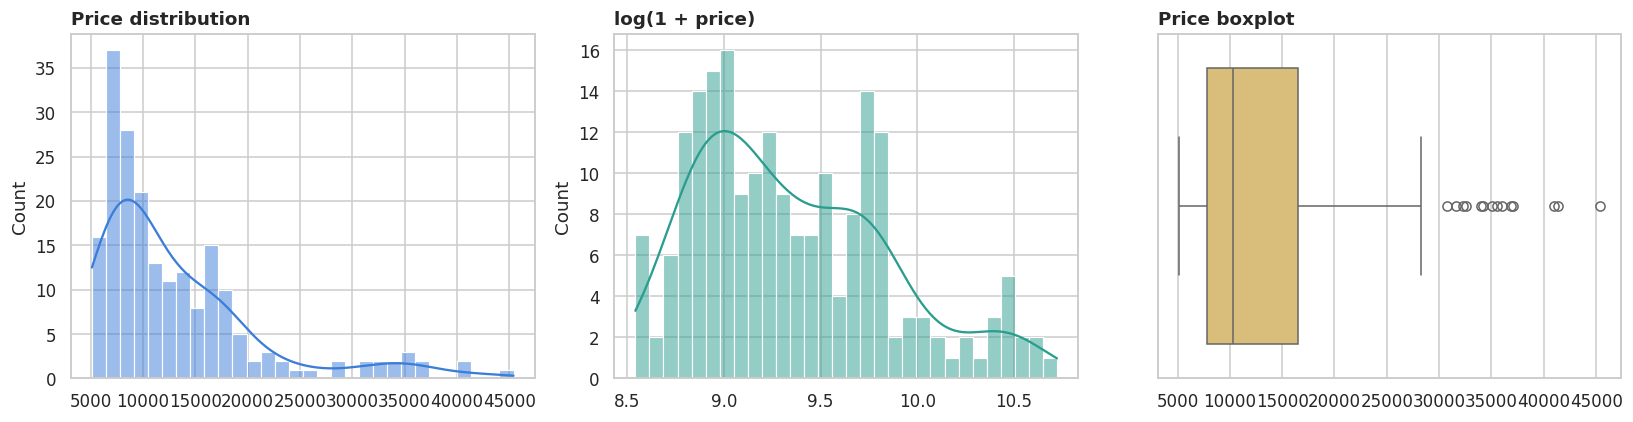

In [24]:
price = df[TARGET]
print(price.describe().to_string())
print(f"\nSkewness: {price.skew():.2f}")
print(f"Excess kurtosis: {price.kurt():.2f}")
print(f"Median / mean: {price.median():,.0f} / {price.mean():,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(price, bins=30, kde=True, ax=axes[0], color="#3B7DD8")
axes[0].set_title("Price distribution")
sns.histplot(np.log1p(price), bins=30, kde=True, ax=axes[1], color="#2A9D8F")
axes[1].set_title("log(1 + price)")
sns.boxplot(x=price, ax=axes[2], color="#E9C46A")
axes[2].set_title("Price boxplot")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.7 Descriptive statistics

In [25]:
print("Numerical columns:")
display(df[NUMERICAL_COLUMNS].describe().T)

print("Categorical columns:")
display(df[CATEGORICAL_COLUMNS].describe().T)

print("Category counts for the main nominal columns:")
for column in ["make", "fuel-type", "body-style", "drive-wheels", "num-of-cylinders"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).to_string())

Numerical columns:


,count,mean,std,min,25%,50%,75%,max
symboling,201.00,0.84,1.25,-2.00,0.00,1.00,2.00,3.00
normalized-losses,164.00,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheel-base,201.00,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.00,174.20,12.32,141.10,166.80,173.20,183.50,208.10
width,201.00,65.89,2.10,60.30,64.10,65.50,66.60,72.00
height,201.00,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.00,"2,555.67",517.30,"1,488.00","2,169.00","2,414.00","2,926.00","4,066.00"
engine-size,201.00,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,197.00,3.33,0.27,2.54,3.15,3.31,3.59,3.94
stroke,197.00,3.26,0.32,2.07,3.11,3.29,3.41,4.17


Categorical columns:


,count,unique,top,freq
make,201,22,toyota,32
fuel-type,201,2,gas,181
aspiration,201,2,std,165
num-of-doors,199,2,four,113
body-style,201,5,sedan,94
drive-wheels,201,3,fwd,118
engine-location,201,2,front,198
engine-type,201,6,ohc,145
num-of-cylinders,201,7,four,157
fuel-system,201,8,mpfi,92


Category counts for the main nominal columns:

make:
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
chevrolet         3
alfa-romero       3
jaguar            3
isuzu             2
renault           2
mercury           1

fuel-type:
fuel-type
gas       181
diesel     20

body-style:
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6

drive-wheels:
drive-wheels
fwd    118
rwd     75
4wd      8

num-of-cylinders:
num-of-cylinders
four      157
six        24
five       10
eight       4
two         4
twelve      1
three       1


## 8. Data Cleaning

Phase 1 cleaning is deliberately minimal. What was done:

- placeholder `?` replaced with `NaN`,
- numeric columns converted to numeric types,
- column names assigned from the documentation.

What was **not** done, by design:

- no rows removed (all genuine observations are retained),
- no imputation or encoding (these belong in the preprocessing pipeline so they are fitted on training data only),
- no values altered.

The intermediate dataset is saved below, and the raw file's fingerprint is re-checked to confirm it is untouched.

In [26]:
CLEAN_PATH = PROCESSED_DIR / "cleaned_auto_imports.csv"
df.to_csv(CLEAN_PATH, index=False)

# Fallback to current directory if RAW_CSV path doesn't exist
actual_csv_path = RAW_CSV if RAW_CSV.exists() else Path.cwd() / "auto_imports.csv"

reloaded = pd.read_csv(CLEAN_PATH)
assert reloaded.shape == df.shape, "Saved file shape differs from in-memory data"
assert sha256_of(actual_csv_path) == raw_hash_before, "Raw CSV was modified!"

print(f"Saved: {CLEAN_PATH.relative_to(PROJECT_ROOT)}  ({reloaded.shape[0]} rows x {reloaded.shape[1]} columns)")
print("Raw CSV fingerprint unchanged: True")

summary = pd.Series({
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Numerical columns": len(NUMERICAL_COLUMNS),
    "Categorical columns": len(CATEGORICAL_COLUMNS),
    "Columns with missing values": int(df.isna().any().sum()),
    "Total missing cells": int(df.isna().sum().sum()),
    "Rows with any missing value": int(df.isna().any(axis=1).sum()),
    "Fully duplicated rows": full_duplicates,
    "Missing target values": int(df[TARGET].isna().sum()),
}, name="Phase 1 summary")
display(summary.to_frame())

Saved: data/processed/cleaned_auto_imports.csv  (201 rows x 26 columns)
Raw CSV fingerprint unchanged: True


,Phase 1 summary
Rows,201
Columns,26
Numerical columns,16
Categorical columns,10
Columns with missing values,6
Total missing cells,51
Rows with any missing value,42
Fully duplicated rows,0
Missing target values,0


## 9. Exploratory Data Analysis

The goal of this section is to understand the data before modelling: how each variable is distributed, how the specification relates to `price`, which variables move together, where outliers sit, and why values are missing.

**A note on leakage.** The EDA below describes all 201 cars. It is used to *understand* the data and to choose what to try. It is not used to compute any value that the model later depends on: imputation values, scaling statistics and encoders are all fitted on the training split only (Sections 11 and 12).

### 9.1 Plot style

In [27]:
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap

BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#9a9a95"
SOFT_BLUE = "#a9c8ef"
INK, MUTED_INK, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
DIVERGING = LinearSegmentedColormap.from_list("blue_neutral_orange", [BLUE, "#f4f3f0", ORANGE])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": MUTED_INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED_INK, "ytick.color": MUTED_INK, "text.color": INK, "font.size": 9,
})


def save_figure(fig, filename):
    """Save a figure into reports/figures and return its relative path."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    return path.relative_to(PROJECT_ROOT)


numeric_predictors = [c for c in NUMERICAL_COLUMNS if c != TARGET]
print("Numeric predictors:", len(numeric_predictors), "| categorical predictors:", len(CATEGORICAL_COLUMNS))

Numeric predictors: 15 | categorical predictors: 10


### 9.2 Numerical distributions

Histograms of all 16 numeric columns (the target `price` is shown in orange). Skewness is printed in each title: values beyond roughly ±1 mean a long tail on one side.

Saved: reports/figures/numeric_distributions.png


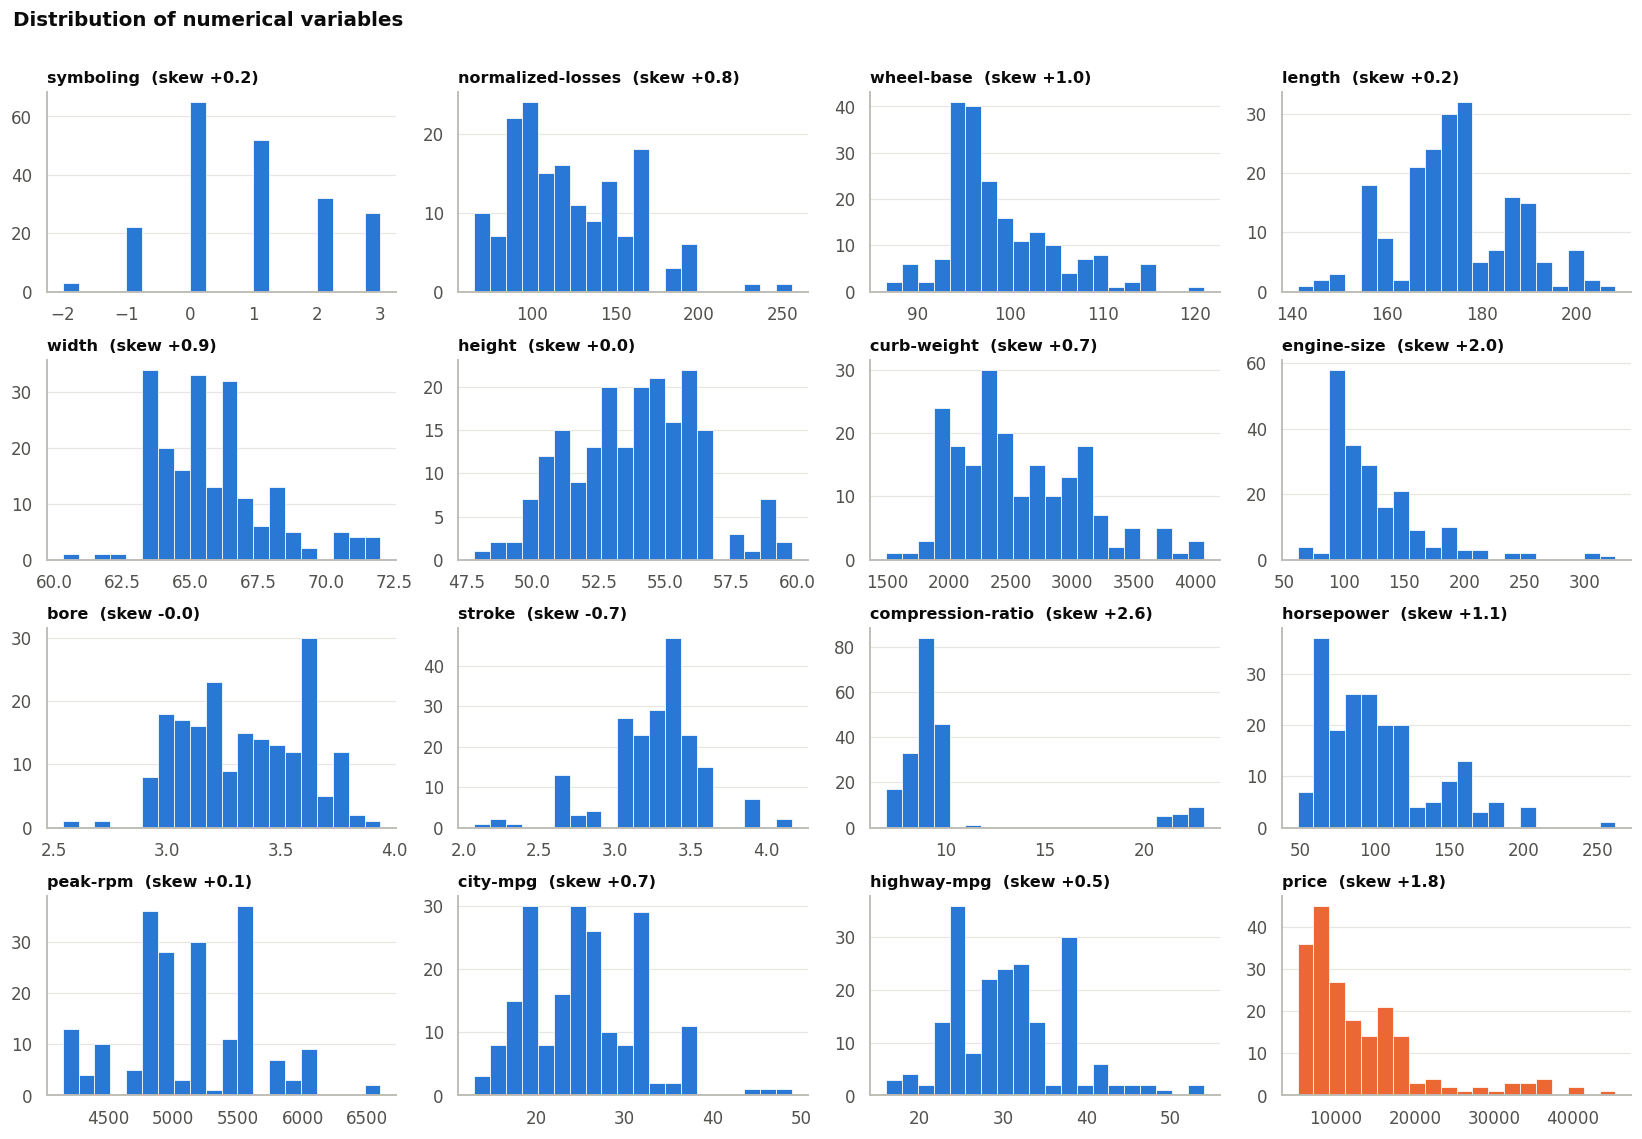

,compression-ratio,engine-size,price,horsepower,wheel-base,width,normalized-losses,curb-weight,city-mpg,highway-mpg,symboling,length,peak-rpm,height,bore,stroke
skewness,2.58,1.98,1.81,1.14,1.03,0.88,0.77,0.71,0.68,0.55,0.20,0.15,0.11,0.03,-0.03,-0.69


In [28]:
fig, axes = plt.subplots(4, 4, figsize=(15, 10.5))
for ax, column in zip(axes.ravel(), NUMERICAL_COLUMNS):
    values = df[column].dropna()
    ax.hist(values, bins=20, color=ORANGE if column == TARGET else BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{column}  (skew {values.skew():+.1f})")
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of numerical variables", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
print("Saved:", save_figure(fig, "numeric_distributions.png"))
plt.show()

skewness = df[NUMERICAL_COLUMNS].skew().sort_values(ascending=False).rename("skewness")
display(skewness.to_frame().T)

### 9.3 Categorical distributions

Counts per category. Heavily unbalanced columns matter because rare categories give a model very little to learn from, and may land only in the test set.

Saved: reports/figures/categorical_counts.png


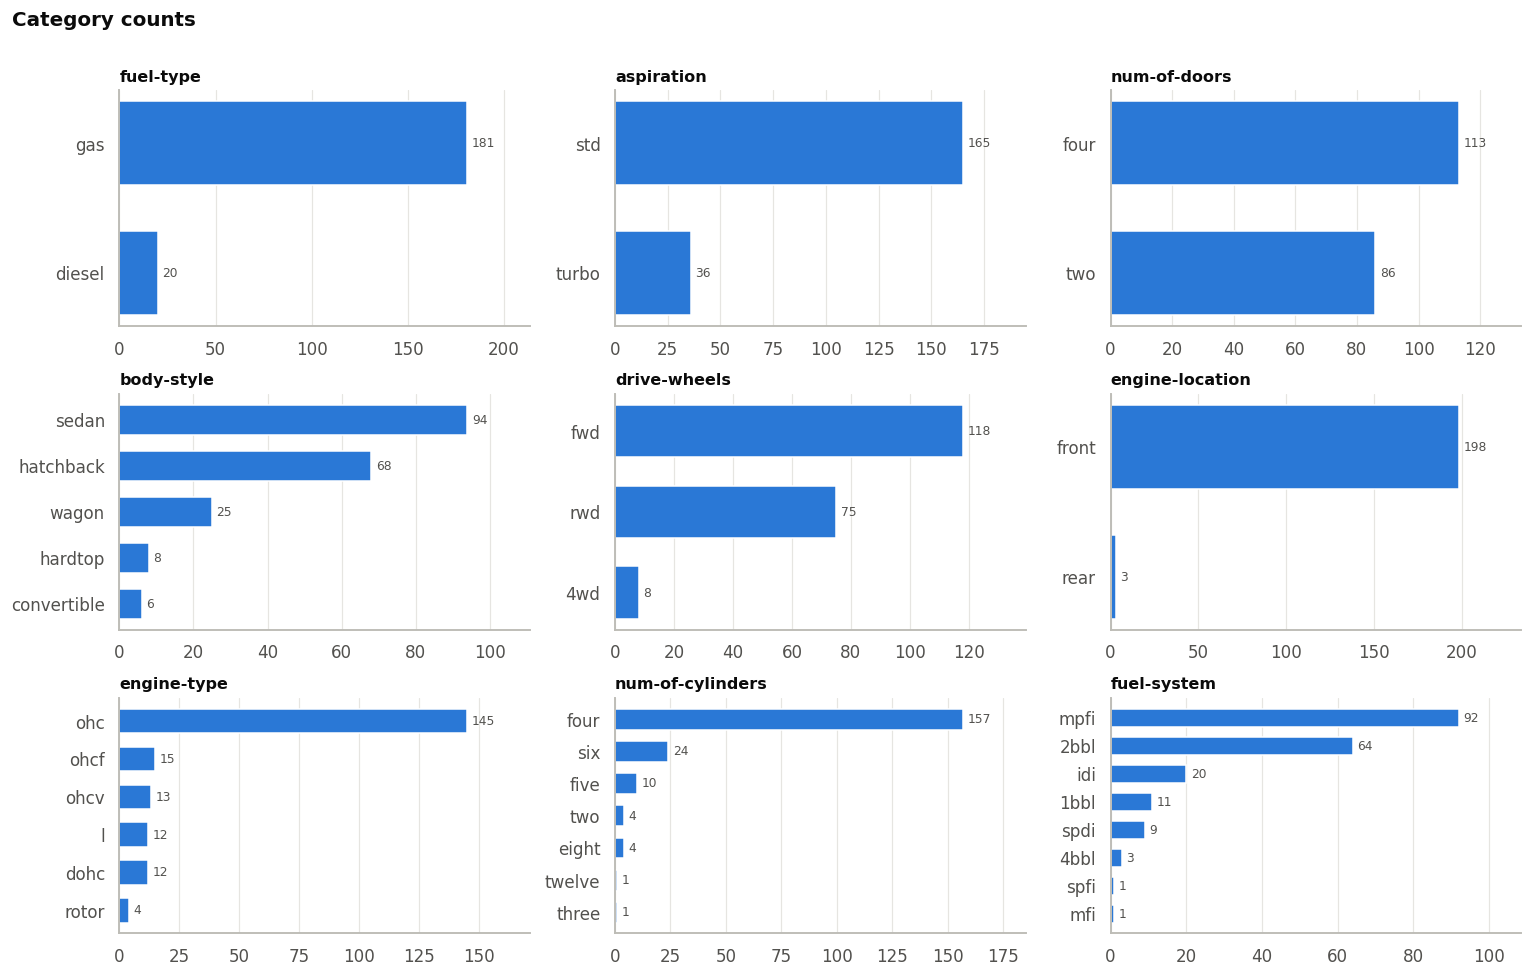

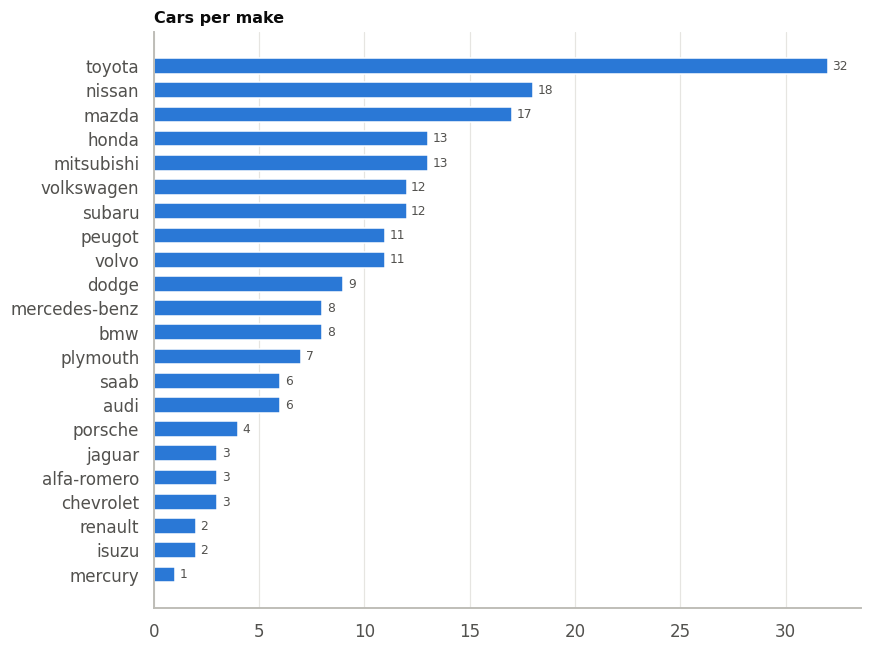

Categories with 3 or fewer cars (column, category -> count):
4bbl         fuel-system         3
alfa-romero  make                3
chevrolet    make                3
isuzu        make                2
jaguar       make                3
mercury      make                1
mfi          fuel-system         1
rear         engine-location     3
renault      make                2
spfi         fuel-system         1
three        num-of-cylinders    1
twelve       num-of-cylinders    1


In [29]:
other_categoricals = [c for c in CATEGORICAL_COLUMNS if c != "make"]

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, column in zip(axes.ravel(), other_categoricals):
    counts = df[column].value_counts().sort_values()
    bars = ax.barh(counts.index.astype(str), counts.values, color=BLUE, height=0.65)
    ax.bar_label(bars, padding=3, fontsize=8, color=MUTED_INK)
    ax.set_title(column)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, counts.max() * 1.18)
fig.suptitle("Category counts", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
print("Saved:", save_figure(fig, "categorical_counts.png"))
plt.show()

make_counts = df["make"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(make_counts.index, make_counts.values, color=BLUE, height=0.65)
ax.bar_label(bars, padding=3, fontsize=8, color=MUTED_INK)
ax.set_title("Cars per make")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

rare = df[CATEGORICAL_COLUMNS].apply(lambda s: s.value_counts()).stack().loc[lambda s: s <= 3]
print("Categories with 3 or fewer cars (column, category -> count):")
print(rare.astype(int).to_string())

### 9.4 Price by category

Box plots of `price` for each categorical column, ordered by median price. The box covers the middle 50% of cars, the line is the median, and dots are statistical outliers.

Saved: reports/figures/price_by_category.png


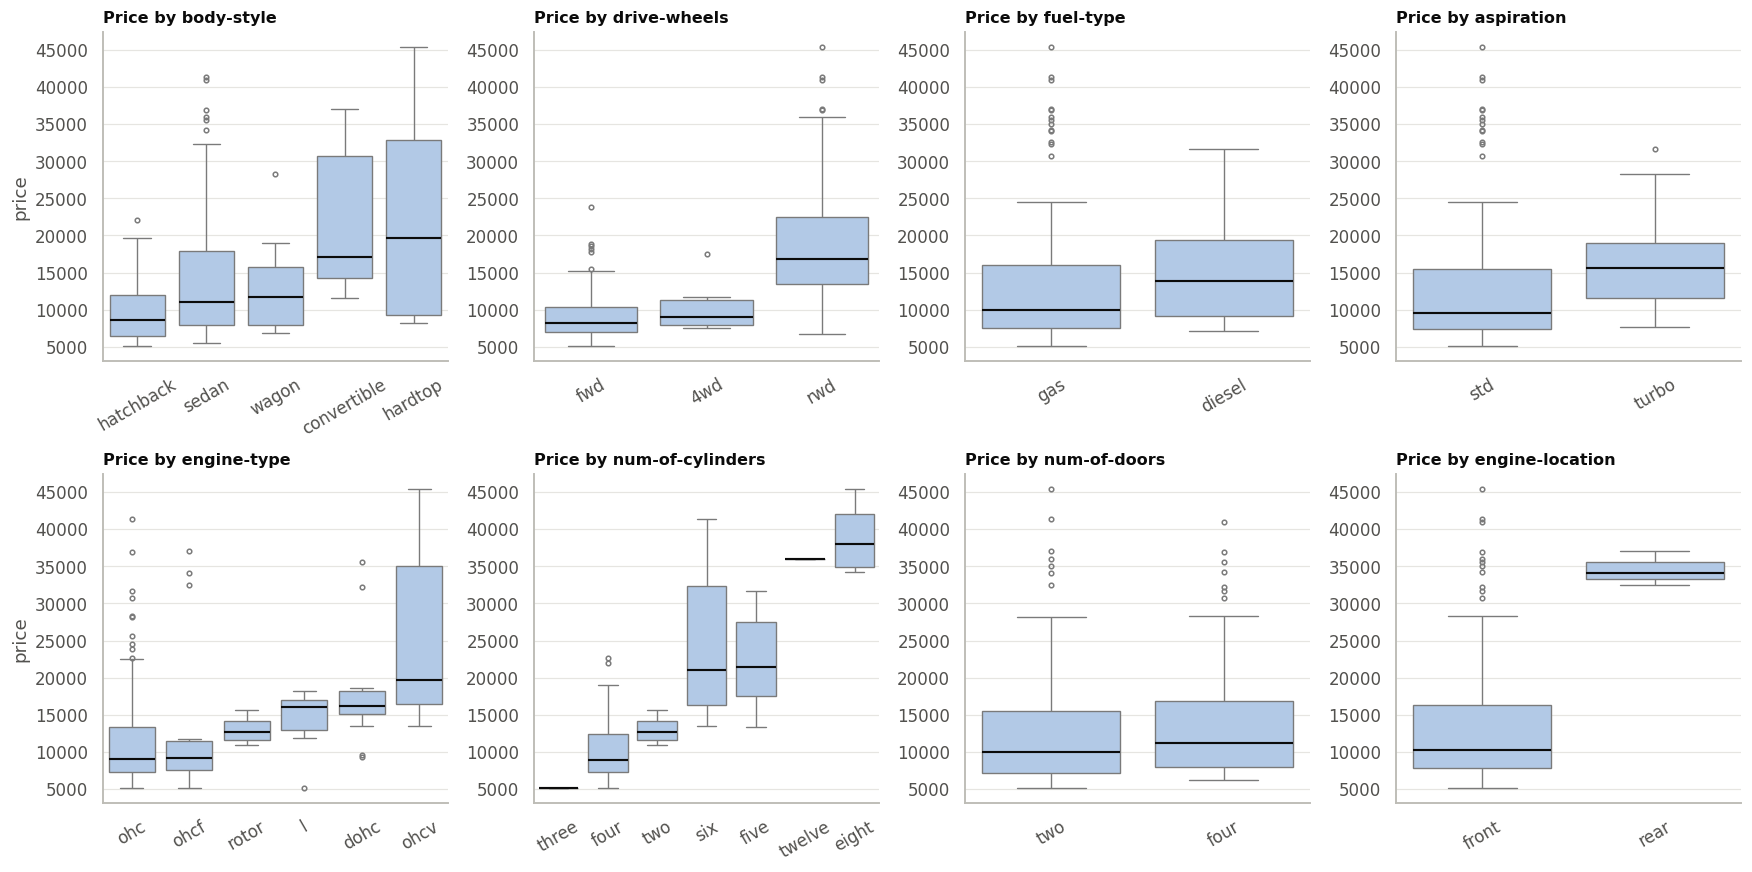

,cars,median_price,min_price,max_price
make,,,,
jaguar,3,"35,550.00",32250,36000
porsche,4,"33,278.00",22018,37028
mercedes-benz,8,"32,892.00",25552,45400
bmw,8,"22,835.00",16430,41315
volvo,11,"18,420.00",12940,22625
audi,6,"17,580.00",13950,23875
peugot,11,"16,630.00",11900,18150
mercury,1,"16,503.00",16503,16503
alfa-romero,3,"16,500.00",13495,16500


In [30]:
price_by_columns = ["body-style", "drive-wheels", "fuel-type", "aspiration",
                    "engine-type", "num-of-cylinders", "num-of-doors", "engine-location"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.ravel(), price_by_columns):
    order = df.groupby(column)[TARGET].median().sort_values().index
    sns.boxplot(data=df, x=column, y=TARGET, order=order, color=SOFT_BLUE, ax=ax,
                linewidth=0.9, fliersize=3, medianprops={"color": INK, "linewidth": 1.4})
    ax.set_title(f"Price by {column}")
    ax.set_xlabel("")
    ax.set_ylabel("price" if ax in axes[:, 0] else "")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
print("Saved:", save_figure(fig, "price_by_category.png"))
plt.show()

make_stats = (df.groupby("make")[TARGET].agg(cars="size", median_price="median", min_price="min", max_price="max")
              .sort_values("median_price", ascending=False))
display(make_stats)

### 9.5 Correlation analysis

The heatmap shows Pearson correlation between every pair of numeric columns (orange positive, blue negative). The ranked table then focuses on `price`, adding Spearman rank correlation, which captures monotonic but non-linear relationships and is less sensitive to outliers.

Saved: reports/figures/correlation_heatmap.png


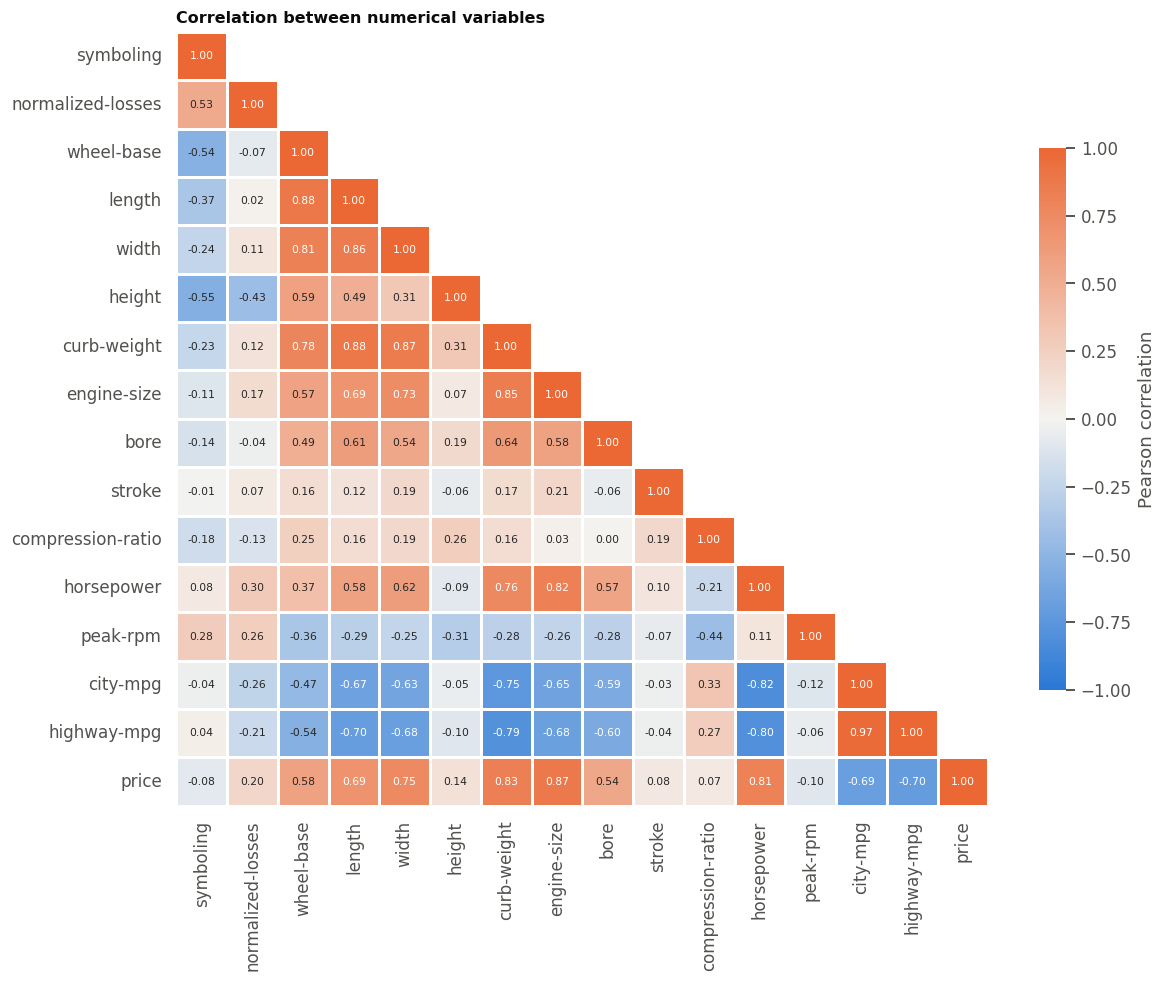

,pearson,spearman
engine-size,0.87,0.83
curb-weight,0.83,0.91
horsepower,0.81,0.85
width,0.75,0.81
highway-mpg,-0.70,-0.83
length,0.69,0.81
city-mpg,-0.69,-0.83
wheel-base,0.58,0.68
bore,0.54,0.65
normalized-losses,0.20,0.19


Saved: reports/figures/correlation_with_price.png


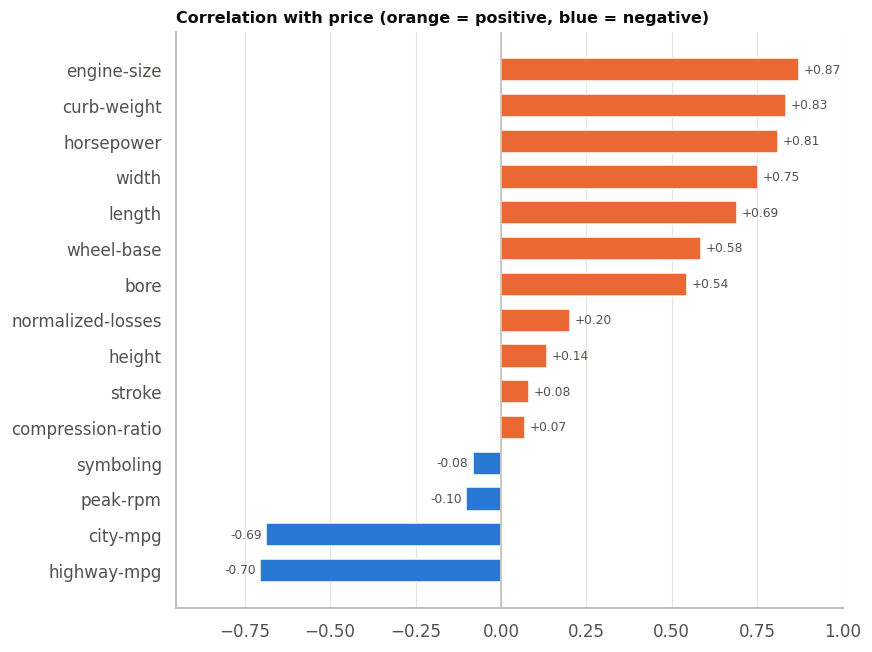

In [31]:
corr = df[NUMERICAL_COLUMNS].corr(method="pearson")
upper_triangle = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=upper_triangle, cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.8, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation between numerical variables")
ax.grid(False)
plt.tight_layout()
print("Saved:", save_figure(fig, "correlation_heatmap.png"))
plt.show()

price_corr = pd.DataFrame({
    "pearson": df[numeric_predictors].corrwith(df[TARGET], method="pearson"),
    "spearman": df[numeric_predictors].corrwith(df[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
display(price_corr)

ordered = price_corr["pearson"].sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(ordered.index, ordered.values, color=[ORANGE if v > 0 else BLUE for v in ordered.values], height=0.65)
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in ordered.values], padding=3, fontsize=8, color=MUTED_INK)
ax.axvline(0, color="#bdbcb6", linewidth=1)
ax.set_xlim(-0.95, 1.0)
ax.set_title("Correlation with price (orange = positive, blue = negative)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
print("Saved:", save_figure(fig, "correlation_with_price.png"))
plt.show()

### 9.6 Relationship of the strongest predictors with price

Scatter plots for the eight numeric predictors with the highest absolute Spearman correlation with `price`, each with a straight-line fit. Curvature around the line points to non-linear relationships that tree-based models can capture and plain linear regression cannot.

Saved: reports/figures/top_features_vs_price.png


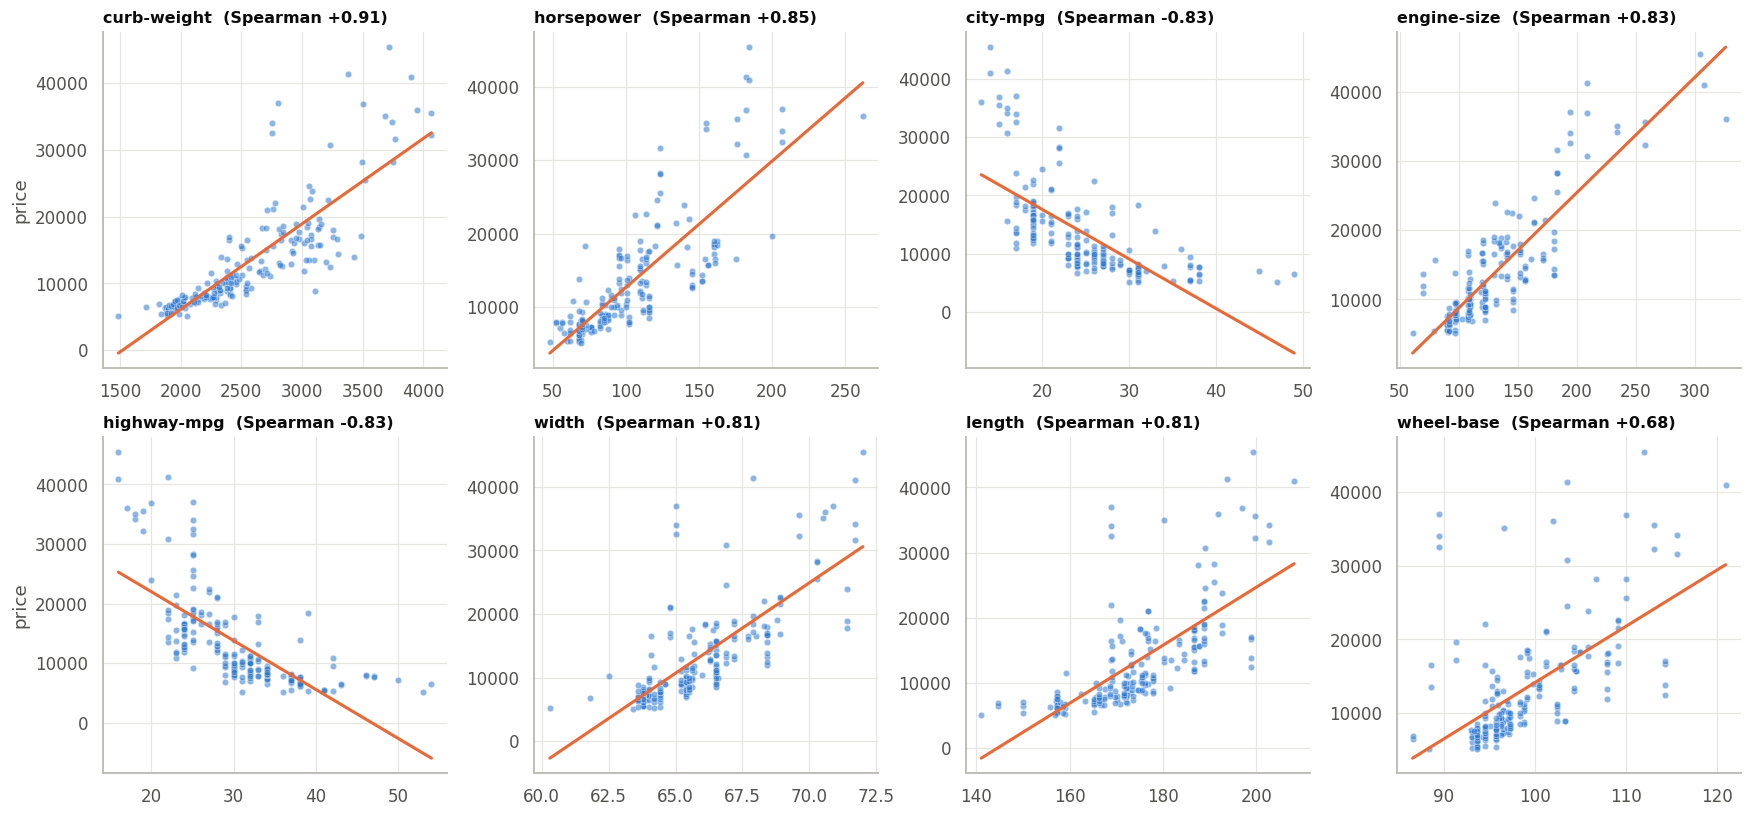

In [32]:
top_features = price_corr["spearman"].abs().sort_values(ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, column in zip(axes.ravel(), top_features):
    pair = df[[column, TARGET]].dropna()
    ax.scatter(pair[column], pair[TARGET], s=18, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.4)
    slope, intercept = np.polyfit(pair[column], pair[TARGET], 1)
    grid_x = np.linspace(pair[column].min(), pair[column].max(), 100)
    ax.plot(grid_x, slope * grid_x + intercept, color=ORANGE, linewidth=2)
    ax.set_title(f"{column}  (Spearman {price_corr.loc[column, 'spearman']:+.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("price" if ax in axes[:, 0] else "")
plt.tight_layout()
print("Saved:", save_figure(fig, "top_features_vs_price.png"))
plt.show()

### 9.7 Multicollinearity

Many size and engine measurements describe the same thing (a bigger car has a longer wheel-base, more weight, a bigger engine). Strongly correlated predictors make linear-model coefficients unstable. Two diagnostics are shown: pairs with |r| ≥ 0.85, and the **variance inflation factor (VIF)**, where values above about 10 indicate serious redundancy. VIF is calculated on median-filled data purely as a diagnostic.

In [33]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

predictor_corr = df[numeric_predictors].corr()
lower_triangle = np.tril(np.ones(predictor_corr.shape, dtype=bool), k=-1)
pair_corr = predictor_corr.where(lower_triangle).stack()
high_pairs = pair_corr[pair_corr.abs() >= 0.85].sort_values(key=abs, ascending=False)
print(f"Predictor pairs with |r| >= 0.85: {len(high_pairs)}")
display(high_pairs.rename("pearson_r").to_frame())

vif_input = sm.add_constant(df[numeric_predictors].apply(lambda s: s.fillna(s.median())))
vif = pd.Series(
    [variance_inflation_factor(vif_input.values, i) for i in range(1, vif_input.shape[1])],
    index=numeric_predictors, name="VIF",
).sort_values(ascending=False)
display(vif.to_frame())
print(f"Predictors with VIF > 10: {int((vif > 10).sum())} of {len(vif)}")

Predictor pairs with |r| >= 0.85: 5


,,pearson_r
highway-mpg,city-mpg,0.97
curb-weight,length,0.88
length,wheel-base,0.88
curb-weight,width,0.87
width,length,0.86


,VIF
city-mpg,27.46
highway-mpg,25.22
curb-weight,16.26
length,9.69
wheel-base,8.88
horsepower,8.82
engine-size,7.15
width,5.97
height,2.53
symboling,2.25


Predictors with VIF > 10: 3 of 15


### 9.8 Outliers

The standard 1.5 × IQR rule flags values far from the middle of each column. Flagged values are **kept**: in this data they are genuine cars (a Jaguar V12, a Mercedes eight-cylinder), not recording errors, and removing them would hide exactly the expensive end the model must handle.

In [34]:
outlier_rows = []
for column in NUMERICAL_COLUMNS:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = int(((values < low) | (values > high)).sum())
    outlier_rows.append({"column": column, "lower_fence": low, "upper_fence": high,
                         "outliers": flagged, "percent": 100 * flagged / len(values)})
outlier_table = pd.DataFrame(outlier_rows).set_index("column").sort_values("outliers", ascending=False)
display(outlier_table)

price_q1, price_q3 = df[TARGET].quantile([0.25, 0.75])
price_upper_fence = price_q3 + 1.5 * (price_q3 - price_q1)
print(f"\nCars priced above the upper fence ({price_upper_fence:,.0f}):")
display(df.loc[df[TARGET] > price_upper_fence,
               ["make", "body-style", "engine-type", "num-of-cylinders", "engine-size", "horsepower", TARGET]]
        .sort_values(TARGET, ascending=False))

,lower_fence,upper_fence,outliers,percent
column,,,,
compression-ratio,7.40,10.60,27,13.43
stroke,2.66,3.86,20,10.15
price,"-5,312.50","29,587.50",14,6.97
width,60.35,70.35,11,5.47
engine-size,33.50,205.50,10,4.98
horsepower,1.00,185.00,5,2.51
wheel-base,82.65,114.25,3,1.49
highway-mpg,11.50,47.50,3,1.49
curb-weight,"1,033.50","4,061.50",2,1.00



Cars priced above the upper fence (29,588):


,make,body-style,engine-type,num-of-cylinders,engine-size,horsepower,price
71,mercedes-benz,hardtop,ohcv,eight,304,184.00,45400
15,bmw,sedan,ohc,six,209,182.00,41315
70,mercedes-benz,sedan,ohcv,eight,308,184.00,40960
125,porsche,convertible,ohcf,six,194,207.00,37028
16,bmw,sedan,ohc,six,209,182.00,36880
46,jaguar,sedan,ohcv,twelve,326,262.00,36000
45,jaguar,sedan,dohc,six,258,176.00,35550
69,mercedes-benz,convertible,ohcv,eight,234,155.00,35056
68,mercedes-benz,sedan,ohcv,eight,234,155.00,34184
124,porsche,hardtop,ohcf,six,194,207.00,34028


### 9.9 Missing-value patterns

Before choosing an imputation strategy it is worth asking whether values are missing at random. `normalized-losses` has by far the most gaps, so it gets the closest look: is its missingness tied to the make of car or to price?

,cars,missing,missing_percent
make,,,
alfa-romero,3,3,100.00
isuzu,2,2,100.00
renault,2,2,100.00
mercury,1,1,100.00
porsche,4,3,75.00
jaguar,3,2,66.67
bmw,8,4,50.00
mercedes-benz,8,3,37.50
peugot,11,4,36.36


Saved: reports/figures/missing_normalized_losses.png


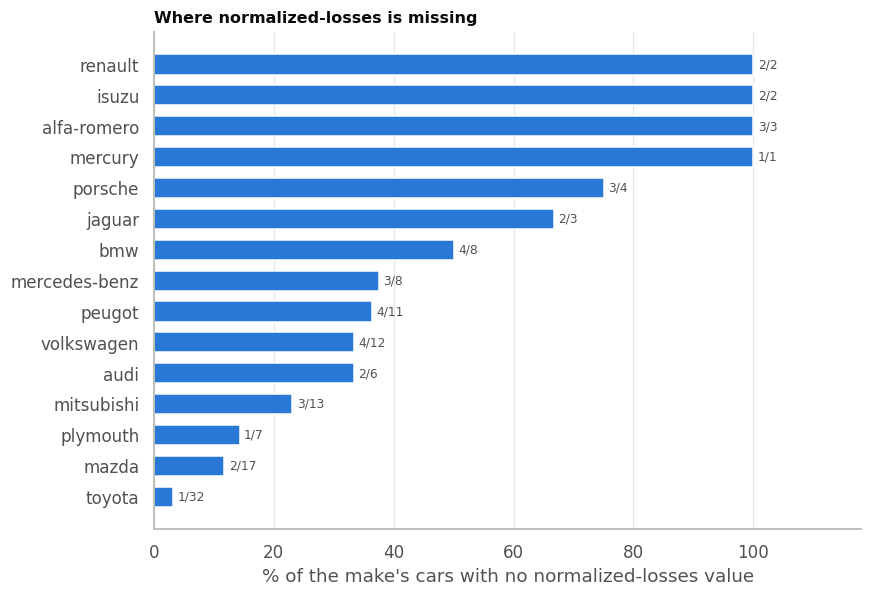

Median price when normalized-losses is missing: 16,500
Median price when it is present:                9,268
Mann-Whitney U test p-value: 0.0000

Cars with a gap in bore, stroke, horsepower, peak-rpm or num-of-doors:


,make,body-style,engine-type,bore,stroke,horsepower,peak-rpm,num-of-doors,price
26,dodge,sedan,ohc,3.03,3.39,102.00,"5,500.00",NaN,8558
52,mazda,hatchback,rotor,NaN,NaN,101.00,"6,000.00",two,10945
53,mazda,hatchback,rotor,NaN,NaN,101.00,"6,000.00",two,11845
54,mazda,hatchback,rotor,NaN,NaN,101.00,"6,000.00",two,13645
55,mazda,hatchback,rotor,NaN,NaN,135.00,"6,000.00",two,15645
60,mazda,sedan,ohc,3.39,3.39,64.00,"4,650.00",NaN,10795
126,renault,wagon,ohc,3.46,3.90,NaN,NaN,four,9295
127,renault,hatchback,ohc,3.46,3.90,NaN,NaN,two,9895


In [35]:
nl_missing = df["normalized-losses"].isna()
missing_by_make = (df.groupby("make")["normalized-losses"]
                   .agg(cars="size", missing=lambda s: int(s.isna().sum())))
missing_by_make["missing_percent"] = 100 * missing_by_make["missing"] / missing_by_make["cars"]
missing_by_make = missing_by_make.sort_values(["missing_percent", "cars"], ascending=False)
display(missing_by_make[missing_by_make["missing"] > 0])

shown = missing_by_make[missing_by_make["missing"] > 0].sort_values("missing_percent")
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(shown.index, shown["missing_percent"], color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{m}/{c}" for m, c in zip(shown["missing"], shown["cars"])],
             padding=3, fontsize=8, color=MUTED_INK)
ax.set_xlim(0, 118)
ax.set_xlabel("% of the make's cars with no normalized-losses value")
ax.set_title("Where normalized-losses is missing")
ax.grid(axis="y", visible=False)
plt.tight_layout()
print("Saved:", save_figure(fig, "missing_normalized_losses.png"))
plt.show()

u_stat, p_value = stats.mannwhitneyu(df.loc[nl_missing, TARGET], df.loc[~nl_missing, TARGET])
print(f"Median price when normalized-losses is missing: {df.loc[nl_missing, TARGET].median():,.0f}")
print(f"Median price when it is present:                {df.loc[~nl_missing, TARGET].median():,.0f}")
print(f"Mann-Whitney U test p-value: {p_value:.4f}")

other_missing_columns = ["bore", "stroke", "horsepower", "peak-rpm", "num-of-doors"]
rows_with_other_gaps = df[df[other_missing_columns].isna().any(axis=1)]
print("\nCars with a gap in bore, stroke, horsepower, peak-rpm or num-of-doors:")
display(rows_with_other_gaps[["make", "body-style", "engine-type"] + other_missing_columns + [TARGET]])

### 9.10 Key findings from the EDA

**Target**
- `price` is right-skewed (skewness 1.81; mean 13,207 vs median 10,295). Fourteen cars (7%) sit above the outlier fence of about 29,600, and all of them are Mercedes-Benz, BMW, Porsche or Jaguar. They are genuine vehicles, so they are kept.

**What drives price**
- The strongest numeric predictors are `engine-size` (r = 0.87), `curb-weight` (0.83) and `horsepower` (0.81). Fuel economy is strongly *negative* (`city-mpg` −0.69, `highway-mpg` −0.70). `stroke`, `compression-ratio`, `peak-rpm`, `symboling` and `height` have almost no linear relationship with price.
- Relationships are **curved, not straight**. Spearman beats Pearson for `curb-weight` (0.91 vs 0.83), and the straight-line fits in 9.6 predict negative prices at the low-price end. This favours tree-based models and a log-transformed target, both tested in Section 13.
- Categorical effects are large. Rear-wheel-drive cars have roughly double the median price of front-wheel-drive ones, the three rear-engine cars (all Porsche) cost about 34,000, and price rises with cylinder count. Convertibles and hardtops cost the most. **Make** is the strongest single signal: Jaguar, Porsche and Mercedes-Benz have median prices above 30,000, Chevrolet 6,295.

**Redundancy**
- `city-mpg` and `highway-mpg` correlate at 0.97, and `curb-weight`, `length`, `wheel-base` and `width` correlate at 0.81–0.88 with each other. Three predictors have VIF above 10 (`city-mpg` 27, `highway-mpg` 25, `curb-weight` 16). Plain linear regression will have unstable coefficients, so regularised models (Ridge, Lasso, ElasticNet) and trees are the better fit.

**Outliers that are not errors**
- Most of the `compression-ratio` "outliers" are diesel engines, which legitimately run at 21–23 against roughly 7–10 for petrol engines. Extreme `engine-size` and `horsepower` belong to the Jaguar V12 and the large Mercedes engines.

**Missing values are not random**
- `normalized-losses` is missing for every Alfa Romeo, Isuzu, Renault and Mercury in the data, and for 3 of 4 Porsches. Cars with the value missing have a much higher median price (16,500 vs 9,268; Mann-Whitney p < 0.0001). Filling them with one global median would give expensive European cars a mid-range value, which is why the pipeline also adds a "was missing" flag.
- The 4 missing `bore`/`stroke` values are all Mazda rotary-engine cars, which have no conventional bore and stroke, so the imputed value is only a placeholder. The 2 missing `horsepower`/`peak-rpm` values are both Renault; the 2 missing `num-of-doors` values are one Dodge and one Mazda.

**Class balance**
- 12 categories have 3 or fewer cars (for example `mercury` 1, `three` cylinders 1, `twelve` cylinders 1, `mfi` 1). A model cannot learn these reliably, so unseen or rare categories must be handled gracefully (`handle_unknown="ignore"` in the encoder).

**Consequences for the next phases:** engineer size and efficiency features (Section 10), impute with the median plus missing flags (Section 11), stratify the split on price (Section 12), and compare linear, regularised and tree-based models with and without a log target (Section 13).

## 10. Feature Engineering

New columns are built from existing ones to expose relationships that a model would otherwise have to discover on its own:

| Feature | Definition | Why |
|---|---|---|
| `cylinders` | `num-of-cylinders` as a number | the words are ordered counts, so a number preserves the order |
| `doors` | `num-of-doors` as a number | same reason; missing values stay missing |
| `power-to-weight` | horsepower ÷ curb-weight | performance relative to size |
| `engine-size-per-cylinder` | engine-size ÷ cylinders | displacement of each cylinder |
| `body-volume-k` | length × width × height ÷ 1000 | a single measure of overall size |
| `avg-mpg` | mean of city and highway mpg | one efficiency measure instead of two near-duplicates |
| `mpg-gap` | highway-mpg − city-mpg | how much better the car does on the highway |
| `bore-stroke-ratio` | bore ÷ stroke | engine geometry |
| `premium-make` | 1 if the make is Audi, BMW, Jaguar, Mercedes-Benz, Porsche, Saab, Volvo or Alfa Romeo | brand positioning |

**No leakage by construction.** Every feature is computed row by row from that row's own columns. Nothing is learned across rows and `price` is never used, so the function can safely run before the split, and it is also placed inside the model pipeline so raw data can be fed straight in later.

`premium-make` encodes a domain assumption about 1985 brand positioning that was fixed in advance, not derived from prices. Its usefulness is checked below and again during model comparison.

In [36]:
CYLINDER_MAP = {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12}
DOOR_MAP = {"two": 2, "four": 4}
PREMIUM_MAKES = {"alfa-romero", "audi", "bmw", "jaguar", "mercedes-benz", "porsche", "saab", "volvo"}
ENGINEERED_FEATURES = [
    "cylinders", "doors", "power-to-weight", "engine-size-per-cylinder", "body-volume-k",
    "avg-mpg", "mpg-gap", "bore-stroke-ratio", "premium-make",
]


def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Add row-wise engineered features. Uses no target values and no statistics from other rows."""
    out = frame.copy()
    out["cylinders"] = out["num-of-cylinders"].map(CYLINDER_MAP)
    out["doors"] = out["num-of-doors"].map(DOOR_MAP)
    out["power-to-weight"] = out["horsepower"] / out["curb-weight"]
    out["engine-size-per-cylinder"] = out["engine-size"] / out["cylinders"]
    out["body-volume-k"] = out["length"] * out["width"] * out["height"] / 1000
    out["avg-mpg"] = (out["city-mpg"] + out["highway-mpg"]) / 2
    out["mpg-gap"] = out["highway-mpg"] - out["city-mpg"]
    out["bore-stroke-ratio"] = out["bore"] / out["stroke"]
    out["premium-make"] = out["make"].isin(PREMIUM_MAKES).astype(int)
    return out


df_fe = engineer_features(df)

unmapped = df_fe.loc[df_fe["cylinders"].isna() & df["num-of-cylinders"].notna(), "num-of-cylinders"].unique()
assert len(unmapped) == 0, f"Unmapped cylinder labels: {unmapped}"
assert np.isfinite(df_fe[ENGINEERED_FEATURES].dropna().to_numpy(dtype=float)).all(), "Non-finite engineered values"

print(f"Columns before: {df.shape[1]}  |  after: {df_fe.shape[1]}  |  rows unchanged: {len(df_fe) == len(df)}")
display(df_fe[["make"] + ENGINEERED_FEATURES].head(6))
display(df_fe[ENGINEERED_FEATURES].describe().T)

Columns before: 26  |  after: 35  |  rows unchanged: True


,make,cylinders,doors,power-to-weight,engine-size-per-cylinder,body-volume-k,avg-mpg,mpg-gap,bore-stroke-ratio,premium-make
0,alfa-romero,4,2.00,0.04,32.50,528.02,24.00,6,1.29,1
1,alfa-romero,4,2.00,0.04,32.50,528.02,24.00,6,1.29,1
2,alfa-romero,6,2.00,0.05,25.33,587.59,22.50,7,0.77,1
3,audi,4,4.00,0.04,27.25,634.82,27.00,6,0.94,1
4,audi,5,4.00,0.04,27.20,636.73,20.00,4,0.94,1
5,audi,5,2.00,0.04,27.20,624.19,22.00,6,0.94,1


,count,mean,std,min,25%,50%,75%,max
cylinders,201.00,4.36,1.06,2.00,4.00,4.00,4.00,12.00
doors,199.00,3.14,0.99,2.00,2.00,4.00,4.00,4.00
power-to-weight,199.00,0.04,0.01,0.02,0.03,0.04,0.04,0.08
engine-size-per-cylinder,201.00,28.94,5.06,19.75,24.50,27.50,32.33,43.00
body-volume-k,201.00,619.58,79.56,452.64,566.49,601.39,674.49,846.01
avg-mpg,201.00,27.93,6.57,15.00,22.50,27.00,32.00,51.50
mpg-gap,201.00,5.51,1.61,0.00,5.00,6.00,7.00,9.00
bore-stroke-ratio,197.00,1.03,0.15,0.77,0.94,0.98,1.07,1.58
premium-make,201.00,0.24,0.43,0.00,0.00,0.00,0.00,1.00


**Do the new features carry signal?** Rank correlation with `price` for the engineered columns (diagnostic only, computed on all rows):

In [37]:
engineered_corr = df_fe[ENGINEERED_FEATURES].corrwith(df_fe[TARGET], method="spearman").rename("spearman_with_price")
display(engineered_corr.sort_values(key=abs, ascending=False).to_frame())

premium_summary = df_fe.groupby("premium-make")[TARGET].agg(cars="size", median_price="median", mean_price="mean")
premium_summary.index = premium_summary.index.map({0: "other makes", 1: "premium makes"})
display(premium_summary)

new_missing = df_fe[ENGINEERED_FEATURES].isna().sum()
print("Missing values in engineered columns (inherited from the source columns):")
print(new_missing[new_missing > 0].to_string())

,spearman_with_price
avg-mpg,-0.83
engine-size-per-cylinder,0.72
body-volume-k,0.71
premium-make,0.67
cylinders,0.57
power-to-weight,0.49
bore-stroke-ratio,0.37
mpg-gap,-0.19
doors,0.13


,cars,median_price,mean_price
premium-make,,,
other makes,152,"8,883.00","9,890.92"
premium makes,49,"20,970.00","23,494.14"


Missing values in engineered columns (inherited from the source columns):
doors                2
power-to-weight      2
bore-stroke-ratio    4


## 11. Data Preprocessing

Preprocessing turns the engineered table into a purely numeric matrix a model can use. It is built as a scikit-learn **pipeline** so that every statistic (medians, category lists, scaling means) is learned from the training data only and then reused unchanged on the test data.

| Step | Applied to | Choice | Reason |
|---|---|---|---|
| Imputation | numeric | median, with a "was missing" flag for columns that have gaps in training | the median resists outliers, and the flag keeps the information that a value was absent (for example `normalized-losses`) |
| Scaling | numeric | standardise (mean 0, std 1) | needed by linear models and KNN; harmless for tree models. `build_feature_pipeline(scale=False)` is available, but every model in Sections 13–16 uses the scaled version |
| Imputation | categorical | most frequent value | only `num-of-doors` has gaps, and it is replaced by the numeric `doors` anyway |
| Encoding | categorical | one-hot, unknown categories ignored | the categories have no natural order, and a make seen only in the test set must not crash prediction |

Columns replaced by an engineered numeric version (`num-of-cylinders`, `num-of-doors`) are dropped from the matrix so the same information is not supplied twice. `price` is the target and is never a feature.

The **target** stays in its original units throughout the notebook. Because `price` is right-skewed, a log-transformed target is a possible future improvement; it was not tested here.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

NUMERIC_FEATURES = [c for c in numeric_predictors] + ENGINEERED_FEATURES
CATEGORICAL_FEATURES = [c for c in CATEGORICAL_COLUMNS if c not in ("num-of-cylinders", "num-of-doors")]

assert TARGET not in NUMERIC_FEATURES + CATEGORICAL_FEATURES, "Target leaked into the feature list"
print(f"Numeric features ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"Categorical features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")


def build_feature_pipeline(scale: bool = True) -> Pipeline:
    """Feature engineering followed by imputation, optional scaling and one-hot encoding."""
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))

    categorical_steps = [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
    column_transformer = ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(numeric_steps), NUMERIC_FEATURES),
            ("categorical", Pipeline(categorical_steps), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )
    return Pipeline([
        ("engineer", FunctionTransformer(engineer_features, validate=False)),
        ("preprocess", column_transformer),
    ])


build_feature_pipeline(scale=True)

Numeric features (24): ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'cylinders', 'doors', 'power-to-weight', 'engine-size-per-cylinder', 'body-volume-k', 'avg-mpg', 'mpg-gap', 'bore-stroke-ratio', 'premium-make']
Categorical features (8): ['make', 'fuel-type', 'aspiration', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'fuel-system']


Pipeline(steps=[('engineer',
                 FunctionTransformer(func=<function engineer_features at 0x78786d91a520>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['symboling',
                                                   'normalized-losses',
                                                   'wheel-base', 'length',
                                                   'width', 'height',
                                                   'curb-weight',...
                                                   'engine-size-per-cylinder',
                                                   'body-volume-k', 'avg-mpg',
                                                   'mpg-gap',
                                                   'bore-stroke-ratio',
                                                   'premium-make']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['make', 'fuel-type',
                                                   'aspiration', 'body-style',
                                                   'drive-wheels',
                                                   'engine-location',
                                                   'engine-type',
                                                   'fuel-system'])]))])

## 12. Train-Test Split

The data is split **80:20 with `random_state=42`** before anything is fitted: 160 cars to train on and 41 held back.

With only 201 cars and a right-skewed price, a purely random split could put most expensive cars in one half. The split is therefore **stratified on price quintiles**, so both halves cover cheap, mid-range and expensive cars. The quintile labels are used only to choose which rows go where; they are never given to a model.

The test set is not touched again until the final evaluation (Section 16). Model selection and tuning use cross-validation on the training set only.

In [39]:
X = df.drop(columns=[TARGET])
y = df[TARGET]
price_quintile = pd.qcut(y, q=5, labels=False)   # used only to stratify the split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_quintile,
)

assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(X_test.index), "Train and test overlap"
assert TARGET not in X_train.columns

print(f"Train: {X_train.shape[0]} rows  ({X_train.shape[0] / len(df):.1%})")
print(f"Test:  {X_test.shape[0]} rows  ({X_test.shape[0] / len(df):.1%})")

split_summary = pd.DataFrame({
    "all": y.describe(), "train": y_train.describe(), "test": y_test.describe(),
}).T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(split_summary)

unseen_makes = sorted(set(X_test["make"]) - set(X_train["make"]))
print(f"Makes appearing only in the test set: {unseen_makes or 'none'}")
print(f"Test cars with missing normalized-losses: {int(X_test['normalized-losses'].isna().sum())} of {len(X_test)}")

Train: 160 rows  (79.6%)
Test:  41 rows  (20.4%)


,count,mean,std,min,25%,50%,75%,max
all,201.00,"13,207.13","7,947.07","5,118.00","7,775.00","10,295.00","16,500.00","45,400.00"
train,160.00,"13,291.86","8,062.27","5,118.00","7,784.75","10,470.00","16,506.00","45,400.00"
test,41.00,"12,876.46","7,567.21","5,348.00","7,609.00","9,298.00","15,580.00","34,184.00"


Makes appearing only in the test set: none
Test cars with missing normalized-losses: 9 of 41


### 12.1 Fitting the preprocessing pipeline on the training data only

The pipeline is **fitted on the training set**, then applied to the test set. Two checks prove no information flows from test to train: the imputation medians equal the *training* medians (and differ from the full-data medians), and the standardised training columns have mean 0 and standard deviation 1 while the test columns do not.

In [40]:
feature_pipeline = build_feature_pipeline(scale=True)
X_train_prepared = feature_pipeline.fit_transform(X_train)
X_test_prepared = feature_pipeline.transform(X_test)

preprocessor = feature_pipeline.named_steps["preprocess"]
prepared_feature_names = list(preprocessor.get_feature_names_out())

print(f"Prepared training matrix: {X_train_prepared.shape}")
print(f"Prepared test matrix:     {X_test_prepared.shape}")
assert X_train_prepared.shape[1] == X_test_prepared.shape[1] == len(prepared_feature_names)
assert not np.isnan(X_train_prepared).any() and not np.isnan(X_test_prepared).any(), "NaN left after preprocessing"
print("OK: no missing values remain and train/test have the same columns.")

numeric_block = preprocessor.named_transformers_["numeric"]
n_numeric_out = len(numeric_block.get_feature_names_out())
n_categorical_out = len(preprocessor.named_transformers_["categorical"].get_feature_names_out())
n_indicators = n_numeric_out - len(NUMERIC_FEATURES)
print(f"\nOutput columns: {n_numeric_out - n_indicators} numeric + {n_indicators} missing-flags + {n_categorical_out} one-hot")

# --- Leakage check 1: imputation values come from the training data
fitted_medians = pd.Series(numeric_block.named_steps["impute"].statistics_, index=NUMERIC_FEATURES)
engineered_train = engineer_features(X_train)[NUMERIC_FEATURES]
engineered_all = engineer_features(X)[NUMERIC_FEATURES]
median_check = pd.DataFrame({
    "fitted_median": fitted_medians,
    "train_median": engineered_train.median(),
    "all_data_median": engineered_all.median(),
}).loc[["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]]
display(median_check)
assert np.allclose(median_check["fitted_median"], median_check["train_median"]), "Imputer did not use training medians"

# --- Leakage check 2: scaling statistics come from the training data
train_matrix = pd.DataFrame(X_train_prepared, columns=prepared_feature_names)
test_matrix = pd.DataFrame(X_test_prepared, columns=prepared_feature_names)
scaled_cols = ["numeric__curb-weight", "numeric__horsepower", "numeric__engine-size"]
display(pd.DataFrame({
    "train_mean": train_matrix[scaled_cols].mean(), "train_std": train_matrix[scaled_cols].std(ddof=0),
    "test_mean": test_matrix[scaled_cols].mean(), "test_std": test_matrix[scaled_cols].std(ddof=0),
}))
assert np.allclose(train_matrix[scaled_cols].mean(), 0, atol=1e-8)
print("OK: the pipeline was fitted on the training data only.")

Prepared training matrix: (160, 82)
Prepared test matrix:     (41, 82)
OK: no missing values remain and train/test have the same columns.

Output columns: 24 numeric + 8 missing-flags + 50 one-hot


,fitted_median,train_median,all_data_median
normalized-losses,115.00,115.00,115.00
bore,3.31,3.31,3.31
stroke,3.35,3.35,3.29
horsepower,95.00,95.00,95.00
peak-rpm,"5,200.00","5,200.00","5,200.00"


,train_mean,train_std,test_mean,test_std
numeric__curb-weight,-0.00,1.00,0.04,0.99
numeric__horsepower,0.00,1.00,-0.12,0.94
numeric__engine-size,0.00,1.00,0.01,0.91


OK: the pipeline was fitted on the training data only.


### 12.2 Saving the split

The two halves are written to `data/processed/` so the exact same split can be inspected or reused. These are the cleaned (pre-engineering) columns plus `price`; the original CSV is untouched.

In [41]:
train_path = PROCESSED_DIR / "train_set.csv"
test_path = PROCESSED_DIR / "test_set.csv"
X_train.assign(**{TARGET: y_train}).to_csv(train_path, index_label="original_row")
X_test.assign(**{TARGET: y_test}).to_csv(test_path, index_label="original_row")

# Fallback to current directory if RAW_CSV path doesn't exist
actual_csv_path = RAW_CSV if RAW_CSV.exists() else Path.cwd() / "auto_imports.csv"

assert sha256_of(actual_csv_path) == raw_hash_before, "Raw CSV was modified!"
print("Saved:", train_path.relative_to(PROJECT_ROOT), "|", test_path.relative_to(PROJECT_ROOT))

phase3_summary = pd.Series({
    "Raw predictor columns": X.shape[1],
    "Engineered features added": len(ENGINEERED_FEATURES),
    "Model input columns after preprocessing": X_train_prepared.shape[1],
    "Training cars": len(X_train),
    "Test cars (held out)": len(X_test),
    "random_state": RANDOM_STATE,
}, name="Phase 3 summary")
display(phase3_summary.to_frame())

Saved: data/processed/train_set.csv | data/processed/test_set.csv


,Phase 3 summary
Raw predictor columns,25
Engineered features added,9
Model input columns after preprocessing,82
Training cars,160
Test cars (held out),41
random_state,42


## 13. Machine Learning Models

In [42]:
## Import the required algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

print("All required libraries imported successfully.")

All required libraries imported successfully.




In this phase, multiple regression algorithms are trained to predict automobile prices.

1. Linear Regression: Predicts price using a linear relationship between features and target.
2. Ridge Regression: Linear regression with L2 regularization to reduce overfitting.
3. Lasso Regression: Uses L1 regularization and can reduce less useful feature coefficients.
4. ElasticNet: Combines L1 and L2 regularization.
5. KNN Regression: Predicts prices using similar vehicles.
6. Decision Tree: Uses decision rules to predict automobile prices.
7. Random Forest: Combines multiple decision trees to improve prediction stability.
8. Extra Trees: Uses randomized decision trees to create an ensemble.
9. Gradient Boosting: Builds models sequentially to correct previous prediction errors.
10. HistGradientBoosting: Uses histogram-based gradient boosting.
11. XGBoost: An optional optimized gradient-boosting algorithm.

In [43]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Lasso Regression": Lasso(
        alpha=0.01,
        max_iter=20000
    ),

    "ElasticNet Regression": ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=20000
    ),

    "KNN Regression": KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOM_STATE
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.05,
        random_state=RANDOM_STATE
    )
}

# Optional XGBoost
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    print("XGBoost successfully added.")

except ImportError:
    print("XGBoost is not installed. Skipping it.")

XGBoost successfully added.


In [44]:
def make_pipeline(estimator):
    # LEGACY helper: preprocessing + model only, WITHOUT the feature-engineering step.
    # It is not used for model selection or evaluation - use make_complete_pipeline() (next cell),
    # which includes feature engineering, preprocessing and the model.
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator)
    ])

print("Preprocessing pipeline function created.")

Preprocessing pipeline function created.


In [45]:
def make_complete_pipeline(estimator):
    # Re-create a pipeline that includes both the feature engineering step AND the preprocessor
    return Pipeline([
        ("engineer", FunctionTransformer(engineer_features, validate=False)),
        ("preprocess", preprocessor),
        ("model", estimator)
    ])

model_results = []
fitted_models = {}

for name, estimator in models.items():

    print(f"Training: {name}")

    # Use the complete pipeline including feature engineering
    pipeline = make_complete_pipeline(estimator)

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)

    train_mae = mean_absolute_error(
        y_train, train_predictions
    )

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    train_r2 = r2_score(
        y_train, train_predictions
    )

    model_results.append({
        "Model": name,
        "Train_MAE": train_mae,
        "Train_RMSE": train_rmse,
        "Train_R2": train_r2
    })

    fitted_models[name] = pipeline

model_results_df = pd.DataFrame(model_results)

display(
    model_results_df.sort_values(
        by="Train_MAE"
    ).round(3)
)

Training: Linear Regression
Training: Ridge Regression
Training: Lasso Regression
Training: ElasticNet Regression
Training: KNN Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: HistGradientBoosting
Training: XGBoost


,Model,Train_MAE,Train_RMSE,Train_R2
7,Extra Trees,23.12,124.69,1.00
4,KNN Regression,23.12,124.69,1.00
10,XGBoost,463.45,628.78,0.99
6,Random Forest,534.11,825.11,0.99
8,Gradient Boosting,720.33,"1,003.59",0.98
0,Linear Regression,890.53,"1,251.62",0.98
2,Lasso Regression,890.58,"1,251.62",0.98
5,Decision Tree,900.98,"1,274.43",0.97
9,HistGradientBoosting,"1,016.81","1,675.26",0.96
3,ElasticNet Regression,"1,019.90","1,440.73",0.97


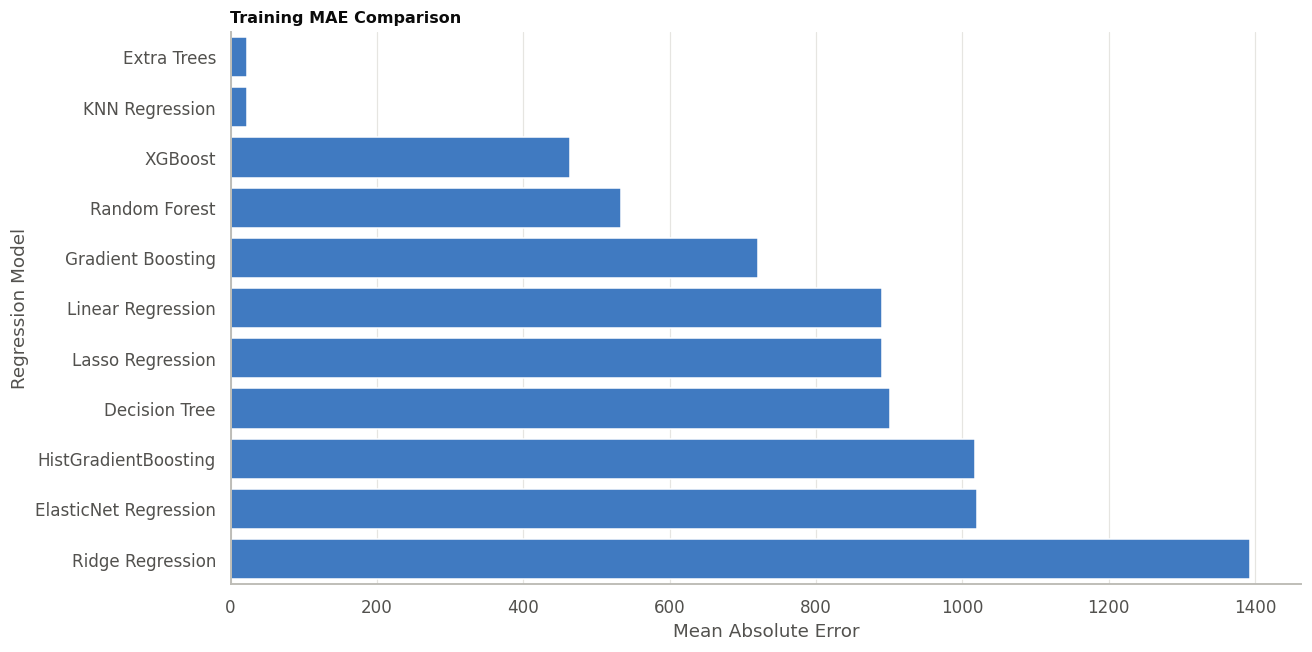

In [46]:
plt.figure(figsize=(12, 6))

sns.barplot(
    color=BLUE,
    data=model_results_df.sort_values("Train_MAE"),
    x="Train_MAE",
    y="Model"
)

plt.title("Training MAE Comparison")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Regression Model")

plt.tight_layout()
plt.show()

## 14. Cross-Validation



Cross-validation evaluates a model using multiple training and validation combinations.

In this project, we use 5-fold cross-validation.

The training dataset is divided into five parts. Each part is used once for validation while the remaining four parts are used for training.

This helps us understand whether a model performs consistently instead of depending on only one validation split.

The test dataset is not used during model selection.

In [47]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results_list = []

for name, estimator in models.items():

    print("Cross-validating:", name)

    # Use the complete pipeline including feature engineering
    pipeline = make_complete_pipeline(estimator)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results_list.append({
        "Model": name,

        "CV_MAE_Mean": -scores["test_MAE"].mean(),
        "CV_MAE_Std": scores["test_MAE"].std(),

        "CV_RMSE_Mean": -scores["test_RMSE"].mean(),
        "CV_RMSE_Std": scores["test_RMSE"].std(),

        "CV_R2_Mean": scores["test_R2"].mean(),
        "CV_R2_Std": scores["test_R2"].std()
    })

cv_results = pd.DataFrame(cv_results_list)

cv_results = cv_results.sort_values(
    by="CV_MAE_Mean"
).reset_index(drop=True)

display(cv_results.round(3))

Cross-validating: Linear Regression
Cross-validating: Ridge Regression
Cross-validating: Lasso Regression
Cross-validating: ElasticNet Regression
Cross-validating: KNN Regression
Cross-validating: Decision Tree
Cross-validating: Random Forest
Cross-validating: Extra Trees
Cross-validating: Gradient Boosting
Cross-validating: HistGradientBoosting
Cross-validating: XGBoost


,Model,CV_MAE_Mean,CV_MAE_Std,CV_RMSE_Mean,CV_RMSE_Std,CV_R2_Mean,CV_R2_Std
0,XGBoost,"1,361.47",314.02,"2,068.81",323.63,0.93,0.01
1,Extra Trees,"1,368.83",383.66,"2,012.34",582.01,0.93,0.04
2,Gradient Boosting,"1,381.85",273.33,"1,989.54",324.57,0.94,0.02
3,Random Forest,"1,414.64",322.83,"2,085.07",514.57,0.93,0.03
4,ElasticNet Regression,"1,760.29",211.59,"2,518.19",388.61,0.89,0.04
5,Decision Tree,"1,771.95",147.23,"2,646.55",330.91,0.88,0.03
6,Ridge Regression,"1,929.26",363.05,"2,869.96",553.09,0.86,0.06
7,HistGradientBoosting,"1,932.93",445.63,"2,898.26",738.92,0.85,0.07
8,KNN Regression,"1,949.80",544.13,"3,040.90","1,006.21",0.84,0.08
9,Lasso Regression,"2,292.85",287.37,"3,898.43","1,031.28",0.70,0.19


In [48]:
cv_results["MAE_Rank"] = (
    cv_results["CV_MAE_Mean"]
    .rank(method="min")
    .astype(int)
)

cv_results = cv_results.sort_values(
    by="MAE_Rank"
).reset_index(drop=True)

display(cv_results)

,Model,CV_MAE_Mean,CV_MAE_Std,CV_RMSE_Mean,CV_RMSE_Std,CV_R2_Mean,CV_R2_Std,MAE_Rank
0,XGBoost,"1,361.47",314.02,"2,068.81",323.63,0.93,0.01,1
1,Extra Trees,"1,368.83",383.66,"2,012.34",582.01,0.93,0.04,2
2,Gradient Boosting,"1,381.85",273.33,"1,989.54",324.57,0.94,0.02,3
3,Random Forest,"1,414.64",322.83,"2,085.07",514.57,0.93,0.02,4
4,ElasticNet Regression,"1,760.29",211.60,"2,518.19",388.61,0.89,0.04,5
5,Decision Tree,"1,771.95",147.23,"2,646.55",330.91,0.88,0.03,6
6,Ridge Regression,"1,929.26",363.05,"2,869.96",553.09,0.86,0.06,7
7,HistGradientBoosting,"1,932.93",445.63,"2,898.25",738.92,0.85,0.07,8
8,KNN Regression,"1,949.80",544.13,"3,040.90","1,006.21",0.84,0.08,9
9,Lasso Regression,"2,292.85",287.37,"3,898.43","1,031.28",0.70,0.19,10


### 14.1 Combined Training vs Cross-Validation Comparison

This table joins the **training** metrics from Section 13 with the **5-fold cross-validation** metrics from this section, one row per model. The two tables are joined on the model name only (each has exactly one row per model), and no metric is invented: training metrics exist for MAE, RMSE and R², and so do the cross-validation metrics.

How to read it:

- **Best models** are ranked by `CV_MAE_Mean` (lower is better). Cross-validation scores come from data the model was not trained on, so they are the fair basis for choosing a model.
- **Overfitting check:** `MAE_Ratio` = CV MAE ÷ training MAE and `R2_Gap` = training R² − CV R². A flexible model that fits its own training data almost perfectly but is much worse on held-out folds is overfitting. Training scores are always optimistic, so treat the flag as a relative guide, not a strict test.
- Flag thresholds (heuristic, editable in the code): `MAE_Ratio` ≥ 5 → **High**, ≥ 2 → **Moderate**, otherwise **Low**.
- The tuned versions of the top ensemble models are compared in Section 15.

,Model,MAE_Rank,Train_MAE,CV_MAE_Mean,CV_MAE_Std,MAE_Gap,MAE_Ratio,Train_RMSE,CV_RMSE_Mean,Train_R2,CV_R2_Mean,R2_Gap,Overfitting_Flag,Selection_Note
0,XGBoost,1,463.45,"1,361.47",314.02,898.02,2.94,628.78,"2,068.81",0.99,0.93,0.06,Moderate,Best by CV MAE
1,Extra Trees,2,23.12,"1,368.83",383.66,"1,345.71",59.19,124.69,"2,012.34",1.00,0.93,0.07,High,Top 3 by CV MAE
2,Gradient Boosting,3,720.33,"1,381.85",273.33,661.52,1.92,"1,003.59","1,989.54",0.98,0.94,0.05,Low,Top 3 by CV MAE
3,Random Forest,4,534.11,"1,414.64",322.83,880.54,2.65,825.11,"2,085.07",0.99,0.93,0.06,Moderate,
4,ElasticNet Regression,5,"1,019.90","1,760.29",211.59,740.40,1.73,"1,440.73","2,518.19",0.97,0.89,0.07,Low,
5,Decision Tree,6,900.98,"1,771.95",147.23,870.96,1.97,"1,274.43","2,646.55",0.97,0.88,0.09,Low,
6,Ridge Regression,7,"1,393.63","1,929.26",363.05,535.63,1.38,"2,033.22","2,869.96",0.94,0.86,0.08,Low,
7,HistGradientBoosting,8,"1,016.81","1,932.93",445.63,916.12,1.90,"1,675.26","2,898.26",0.96,0.85,0.10,Low,
8,KNN Regression,9,23.12,"1,949.80",544.13,"1,926.68",84.31,124.69,"3,040.90",1.00,0.84,0.16,High,
9,Lasso Regression,10,890.58,"2,292.85",287.37,"1,402.28",2.58,"1,251.62","3,898.43",0.98,0.70,0.27,Moderate,


Best model by cross-validation MAE: XGBoost (CV MAE 1,361 +/- 314)
Top 3 by CV MAE: ['XGBoost', 'Extra Trees', 'Gradient Boosting']
Models within one CV standard deviation of the best (not clearly distinguishable): ['XGBoost', 'Extra Trees', 'Gradient Boosting', 'Random Forest']
High overfitting flag:     ['Extra Trees', 'KNN Regression']
Moderate overfitting flag: ['XGBoost', 'Random Forest', 'Lasso Regression', 'Linear Regression']


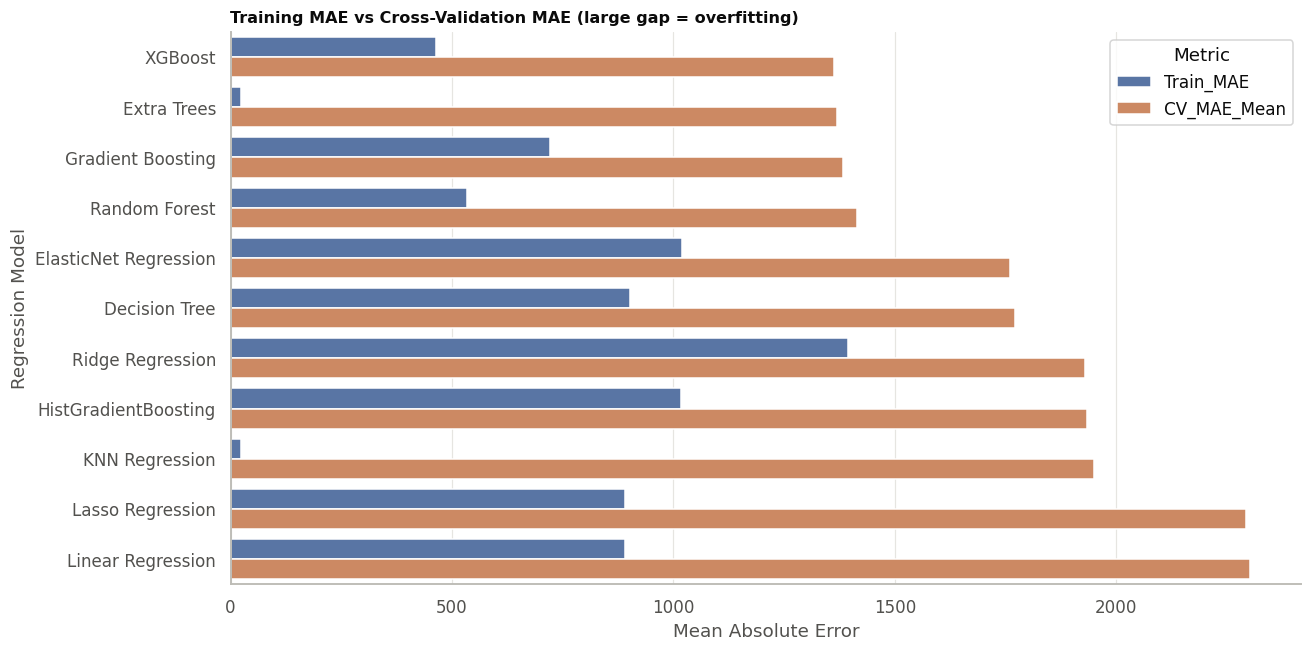

In [49]:
# Combined training + cross-validation comparison (untuned models from Sections 13-14).
train_cols = ["Model", "Train_MAE", "Train_RMSE", "Train_R2"]
cv_cols = ["Model", "CV_MAE_Mean", "CV_MAE_Std", "CV_RMSE_Mean", "CV_RMSE_Std",
           "CV_R2_Mean", "CV_R2_Std", "MAE_Rank"]

# Inspect before merging: the expected columns must exist and both tables must cover the same models.
for frame_name, frame, needed in [("model_results_df", model_results_df, train_cols),
                                  ("cv_results", cv_results, cv_cols)]:
    absent = [c for c in needed if c not in frame.columns]
    assert not absent, f"{frame_name} is missing columns: {absent}"
assert set(model_results_df["Model"]) == set(cv_results["Model"]), (
    "Training and cross-validation tables cover different models: "
    f"{set(model_results_df['Model']) ^ set(cv_results['Model'])}"
)

combined_comparison = model_results_df[train_cols].merge(
    cv_results[cv_cols], on="Model", how="inner", validate="one_to_one"
)

combined_comparison["MAE_Gap"] = combined_comparison["CV_MAE_Mean"] - combined_comparison["Train_MAE"]
# A training MAE of exactly 0 is a perfect in-sample fit (the extreme case of overfitting) -> ratio = infinity.
combined_comparison["MAE_Ratio"] = np.where(
    combined_comparison["Train_MAE"] > 0,
    combined_comparison["CV_MAE_Mean"] / combined_comparison["Train_MAE"].where(combined_comparison["Train_MAE"] > 0, 1),
    np.inf,
)
combined_comparison["R2_Gap"] = combined_comparison["Train_R2"] - combined_comparison["CV_R2_Mean"]

HIGH_RATIO, MODERATE_RATIO = 5.0, 2.0   # heuristic thresholds for the overfitting flag
combined_comparison["Overfitting_Flag"] = np.select(
    [combined_comparison["MAE_Ratio"] >= HIGH_RATIO, combined_comparison["MAE_Ratio"] >= MODERATE_RATIO],
    ["High", "Moderate"],
    default="Low",
)

combined_comparison = combined_comparison.sort_values("CV_MAE_Mean").reset_index(drop=True)
combined_comparison["Selection_Note"] = ""
combined_comparison.loc[0, "Selection_Note"] = "Best by CV MAE"
combined_comparison.loc[1:2, "Selection_Note"] = "Top 3 by CV MAE"

column_order = ["Model", "MAE_Rank", "Train_MAE", "CV_MAE_Mean", "CV_MAE_Std", "MAE_Gap", "MAE_Ratio",
                "Train_RMSE", "CV_RMSE_Mean", "Train_R2", "CV_R2_Mean", "R2_Gap",
                "Overfitting_Flag", "Selection_Note"]
display(combined_comparison[column_order].round(3))

best_row = combined_comparison.iloc[0]
print(f"Best model by cross-validation MAE: {best_row['Model']} "
      f"(CV MAE {best_row['CV_MAE_Mean']:,.0f} +/- {best_row['CV_MAE_Std']:,.0f})")
print("Top 3 by CV MAE:", combined_comparison["Model"].head(3).tolist())
within_noise = combined_comparison.loc[
    combined_comparison["CV_MAE_Mean"] <= best_row["CV_MAE_Mean"] + best_row["CV_MAE_Std"], "Model"
].tolist()
print("Models within one CV standard deviation of the best (not clearly distinguishable):", within_noise)
print("High overfitting flag:    ", combined_comparison.loc[combined_comparison["Overfitting_Flag"] == "High", "Model"].tolist())
print("Moderate overfitting flag:", combined_comparison.loc[combined_comparison["Overfitting_Flag"] == "Moderate", "Model"].tolist())

plot_data = combined_comparison.melt(
    id_vars="Model", value_vars=["Train_MAE", "CV_MAE_Mean"], var_name="Metric", value_name="MAE"
)
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_data, x="MAE", y="Model", hue="Metric", order=combined_comparison["Model"], palette="deep")
plt.title("Training MAE vs Cross-Validation MAE (large gap = overfitting)")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Regression Model")
plt.tight_layout()
plt.show()

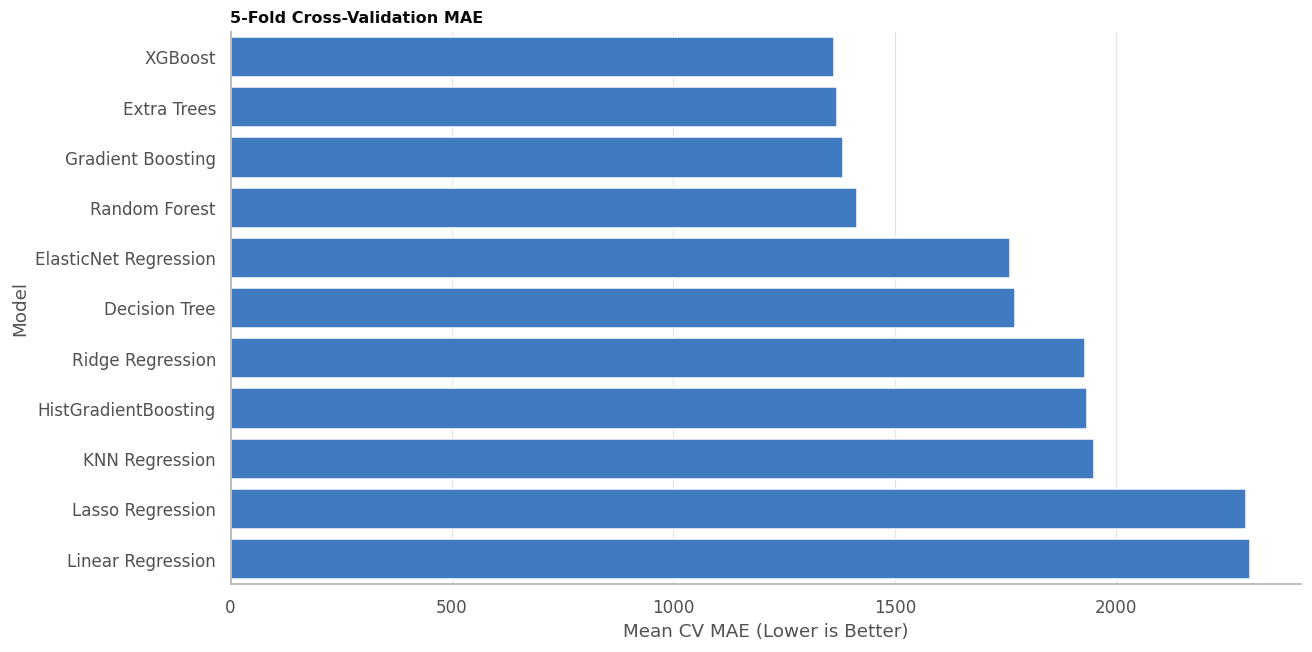

In [50]:
plt.figure(figsize=(12, 6))

sns.barplot(
    color=BLUE,
    data=cv_results,
    x="CV_MAE_Mean",
    y="Model"
)

plt.title("5-Fold Cross-Validation MAE")
plt.xlabel("Mean CV MAE (Lower is Better)")

plt.tight_layout()
plt.show()

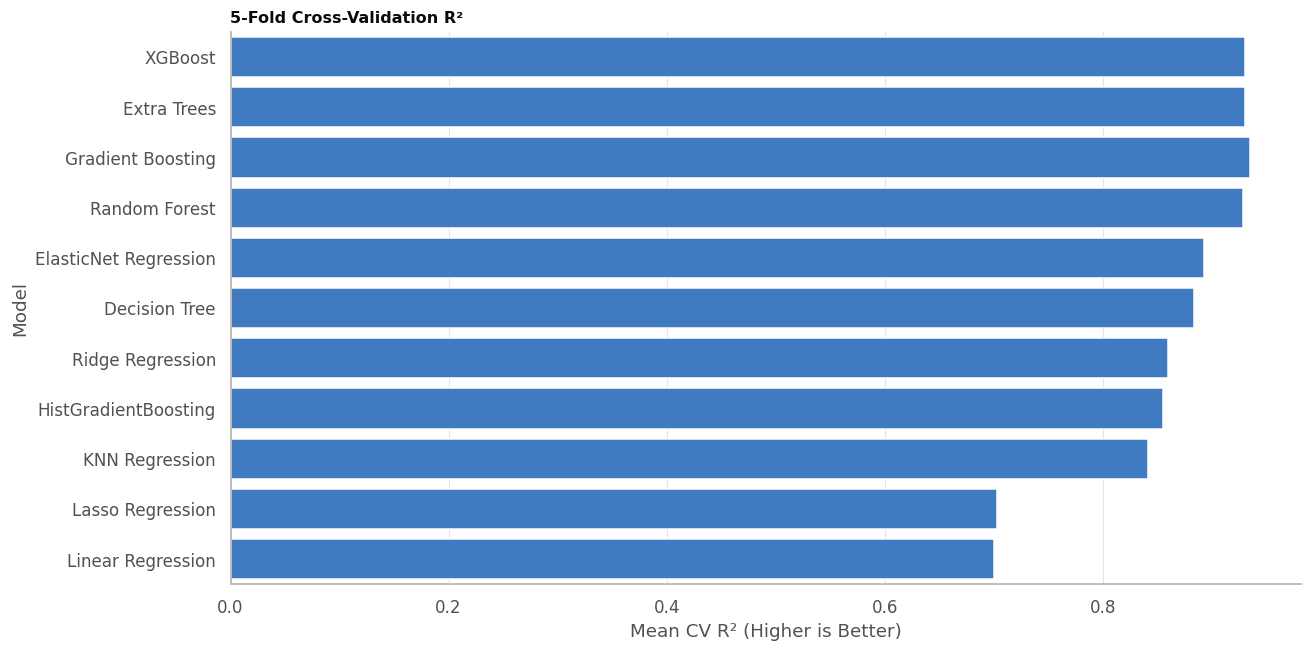

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    color=BLUE,
    data=cv_results,
    x="CV_R2_Mean",
    y="Model"
)

plt.title("5-Fold Cross-Validation R²")
plt.xlabel("Mean CV R² (Higher is Better)")

plt.tight_layout()
plt.show()

## 15. Hyperparameter Tuning


Hyperparameters control how a machine learning algorithm learns.

For example, Random Forest uses the number of decision trees, maximum depth and minimum samples per leaf.

RandomizedSearchCV tests a selection of parameter combinations using cross-validation.

The best parameters are selected using negative mean absolute error.

The test dataset is not used during tuning.

In [52]:
tunable_models = [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting"
]

available_candidates = [
    name for name in cv_results["Model"].tolist()
    if name in tunable_models
]

top_candidates = available_candidates[:3]

print("Models selected for tuning:")
print(top_candidates)

Models selected for tuning:
['Extra Trees', 'Gradient Boosting', 'Random Forest']


In [53]:
param_spaces = {

    "Random Forest": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__max_depth": [None, 4, 6, 8, 12],
        "model__min_samples_split": [2, 4, 6],
        "model__min_samples_leaf": [1, 2, 3],
        "model__max_features": [0.6, 0.8, 1.0]
    },

    "Extra Trees": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__max_depth": [None, 4, 6, 8, 12],
        "model__min_samples_split": [2, 4, 6],
        "model__min_samples_leaf": [1, 2, 3],
        "model__max_features": [0.6, 0.8, 1.0]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200, 300],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [1, 2, 3],
        "model__subsample": [0.7, 0.85, 1.0]
    }
}

In [54]:
from sklearn.model_selection import RandomizedSearchCV

best_searches = {}
tuning_results = []

for name in top_candidates:

    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=make_complete_pipeline(models[name]),
        param_distributions=param_spaces[name],
        n_iter=10,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_searches[name] = search

    tuning_results.append({
        "Model": name,
        "Best_CV_MAE": -search.best_score_,
        "Best_Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Best_CV_MAE"
).reset_index(drop=True)

display(tuning_df)


Tuning Extra Trees...

Tuning Gradient Boosting...

Tuning Random Forest...


,Model,Best_CV_MAE,Best_Parameters
0,Gradient Boosting,"1,311.81","{'model__subsample': 1.0, 'model__n_estimators..."
1,Extra Trees,"1,359.33","{'model__n_estimators': 200, 'model__min_sampl..."
2,Random Forest,"1,414.64","{'model__n_estimators': 200, 'model__min_sampl..."


In [55]:
comparison_rows = []

for name, search in best_searches.items():

    original_score = cv_results.loc[
        cv_results["Model"] == name,
        "CV_MAE_Mean"
    ].iloc[0]

    comparison_rows.append({
        "Model": name,
        "Original_CV_MAE": original_score,
        "Tuned_CV_MAE": -search.best_score_,
        "Improvement": original_score - (-search.best_score_)
    })

tuned_comparison = pd.DataFrame(comparison_rows)

display(tuned_comparison.round(3))

,Model,Original_CV_MAE,Tuned_CV_MAE,Improvement
0,Extra Trees,"1,368.83","1,359.33",9.50
1,Gradient Boosting,"1,381.85","1,311.81",70.05
2,Random Forest,"1,414.64","1,414.64",0.00


## 16. Final Evaluation, Explainable AI and Reports

In [56]:
from sklearn.base import clone

# Start with all original models and their cross-validated MAE (computed on the training set only).
candidate_scores = {
    row["Model"]: row["CV_MAE_Mean"]
    for _, row in cv_results.iterrows()
}

# Every candidate is a COMPLETE pipeline: feature engineering -> preprocessing -> model.
# clone() gives each candidate its own unfitted copy, so nothing is shared with objects fitted earlier.
candidate_pipelines = {
    name: clone(make_complete_pipeline(models[name]))
    for name in models
}

# Replace original scores with tuned CV scores (the tuned estimators are already complete pipelines).
for name, search in best_searches.items():

    candidate_scores[name] = -search.best_score_

    candidate_pipelines[name] = search.best_estimator_

# Select using CV MAE on the training data, not test MAE.
best_model_name = min(
    candidate_scores,
    key=candidate_scores.get
)

best_model = candidate_pipelines[best_model_name]

assert list(best_model.named_steps) == ["engineer", "preprocess", "model"], (
    "best_model must be the complete pipeline (engineer -> preprocess -> model)"
)

print("Selected model:", best_model_name)
print("Training CV MAE:", candidate_scores[best_model_name])

Selected model: Gradient Boosting
Training CV MAE: 1311.8065067395096


### 16.1 Final test-set evaluation and why Adjusted R² is not reported

The selected model is fitted on the **complete training set** and then evaluated **once** on the untouched test set.

**Adjusted R² is intentionally not reported.** It is defined for linear regression, where the penalty depends on the number of fitted coefficients. The selected model is a nonlinear tree ensemble: its complexity is not the number of input columns, so subtracting a penalty based on the original predictor count does not measure anything meaningful. The earlier version of this notebook also had only 41 test cars against 25 raw predictors, which made the penalty arbitrary and the figure misleading. Model quality is instead judged with **MAE, MSE, RMSE, R², Median Absolute Error and MAPE** on the test set, together with the cross-validated scores from Section 14.

In [57]:
from sklearn.metrics import median_absolute_error

# Fit the complete pipeline using training data only.
best_model.fit(X_train, y_train)

# One final prediction on the untouched test dataset.
best_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, best_pred)

mse = mean_squared_error(y_test, best_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, best_pred)

median_ae = median_absolute_error(y_test, best_pred)

# Adjusted R2 is deliberately NOT calculated: it is not a valid measure for a nonlinear ensemble model
# (see the Markdown cell above).

nonzero_actual = np.asarray(y_test) != 0

mape = (
    np.mean(
        np.abs(
            (np.asarray(y_test)[nonzero_actual] -
             best_pred[nonzero_actual]) /
            np.asarray(y_test)[nonzero_actual]
        )
    ) * 100
    if nonzero_actual.any()
    else np.nan
)

final_metrics = {
    "Selected_Model": best_model_name,
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "R2": r2,
    "Median_Absolute_Error": median_ae,
    "MAPE_Percentage": mape
}

final_metrics_df = pd.DataFrame(
    [final_metrics]
)

display(final_metrics_df.round(3))

,Selected_Model,MAE,MSE,RMSE,R2,Median_Absolute_Error,MAPE_Percentage
0,Gradient Boosting,"1,420.04","3,738,749.99","1,933.59",0.93,"1,105.36",11.29


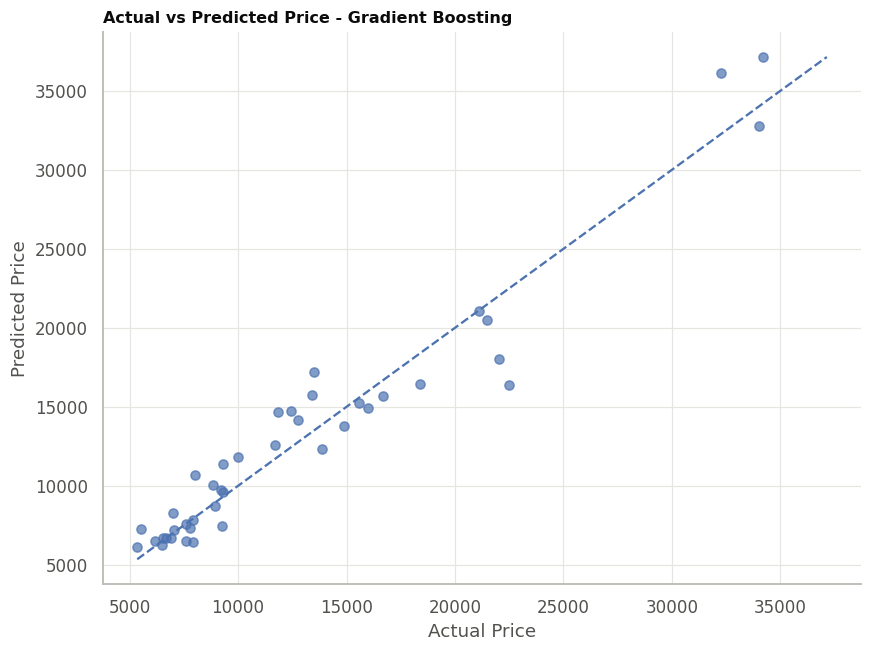

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_pred,
    alpha=0.7
)

min_value = min(np.min(y_test), np.min(best_pred))
max_value = max(np.max(y_test), np.max(best_pred))

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title(
    f"Actual vs Predicted Price - {best_model_name}"
)

plt.tight_layout()
plt.show()

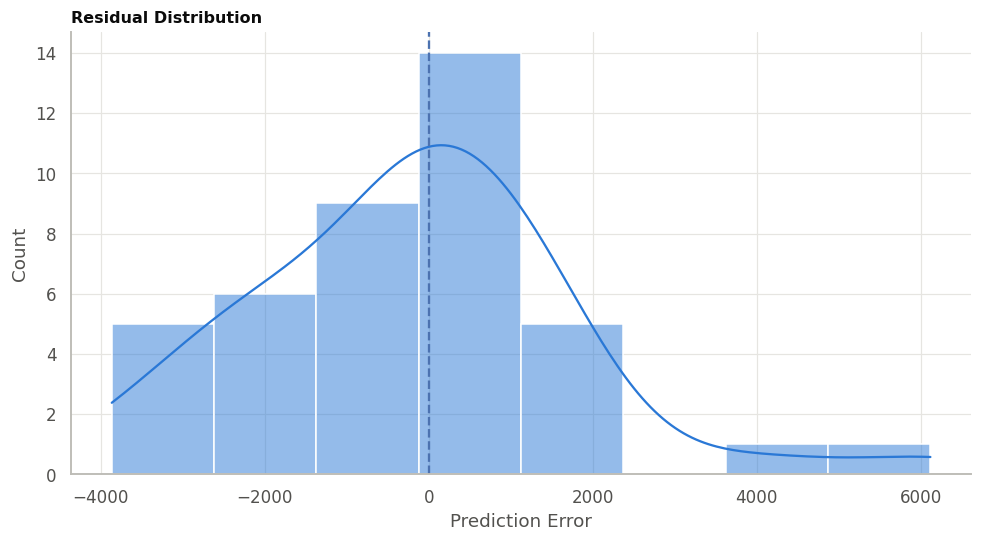

In [59]:
residuals = np.asarray(y_test) - best_pred

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    kde=True,
    color=BLUE
)

plt.axvline(0, linestyle="--")

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")

plt.tight_layout()
plt.show()

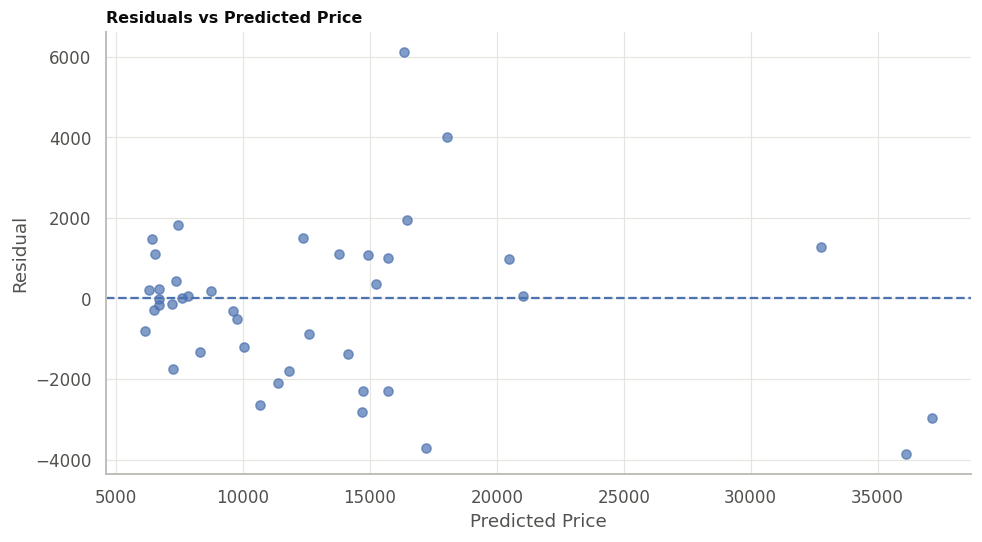

In [60]:
plt.figure(figsize=(9, 5))

plt.scatter(
    best_pred,
    residuals,
    alpha=0.7
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual")

plt.title("Residuals vs Predicted Price")

plt.tight_layout()
plt.show()

In [61]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance_Mean",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance_Mean,Importance_Std
16,engine-size,"1,317.87",232.67
13,curb-weight,894.60,158.83
2,make,651.58,152.69
21,horsepower,238.01,69.08
9,wheel-base,235.89,78.54
11,width,96.28,81.03
12,height,81.61,61.80
22,peak-rpm,73.64,36.27
24,highway-mpg,68.52,74.01
7,drive-wheels,49.62,39.23


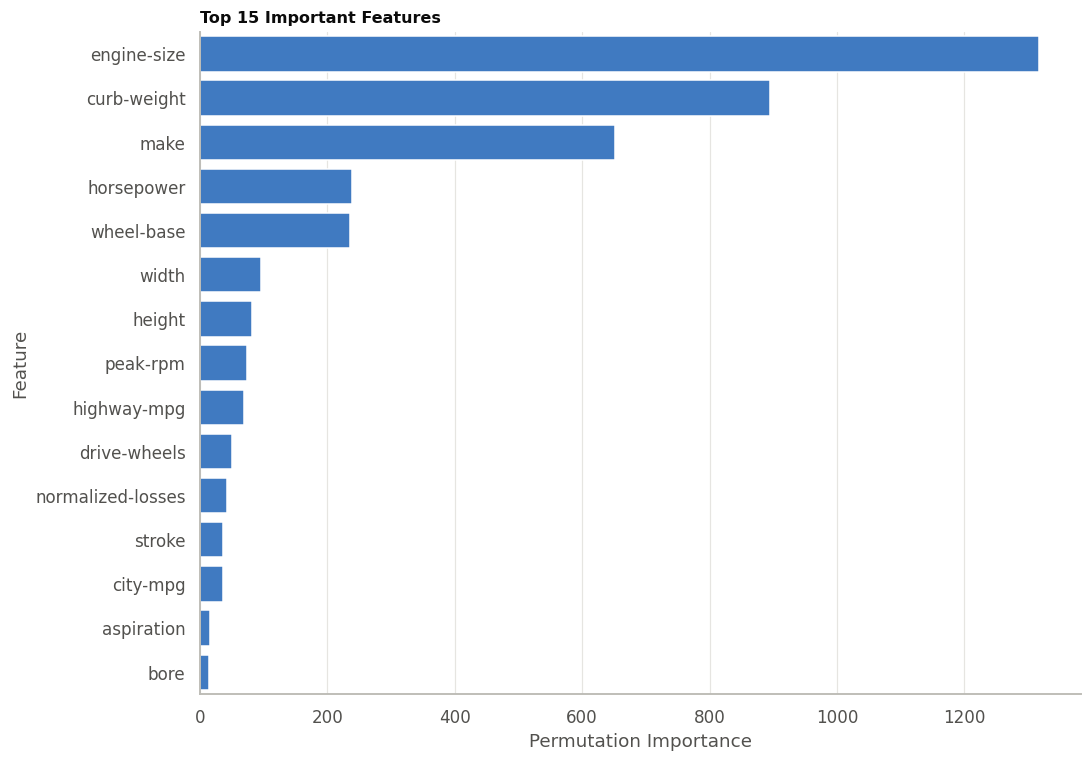

In [62]:
plt.figure(figsize=(10, 7))

sns.barplot(
    color=BLUE,
    data=feature_importance.head(15),
    x="Importance_Mean",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.xlabel("Permutation Importance")

plt.tight_layout()
plt.show()

### 16.2 SHAP explainability

SHAP must be computed on exactly the matrix the final model sees. The fitted pipeline has three steps (`engineer` → `preprocess` → `model`), so the test data is first passed through **feature engineering and preprocessing** (`best_model[:-1]`), and SHAP values are then calculated for the fitted final estimator. The column names come from the fitted preprocessor, so they match the transformed matrix one-to-one (numeric features, missing-value flags and one-hot categories). Numeric values are standardised, so colours in the plot show high/low *relative to the training data*.

`TreeExplainer` is used only for estimators it supports (decision tree, random forest, extra trees, gradient boosting, XGBoost/LightGBM); any other model falls back to the model-agnostic `shap.Explainer`. If `shap` is missing or incompatible with the installed library versions, the cell prints the reason and the notebook continues; **permutation importance (above) remains the alternative explainability method.**

SHAP computed with TreeExplainer for GradientBoostingRegressor on 41 test cars x 82 transformed features.


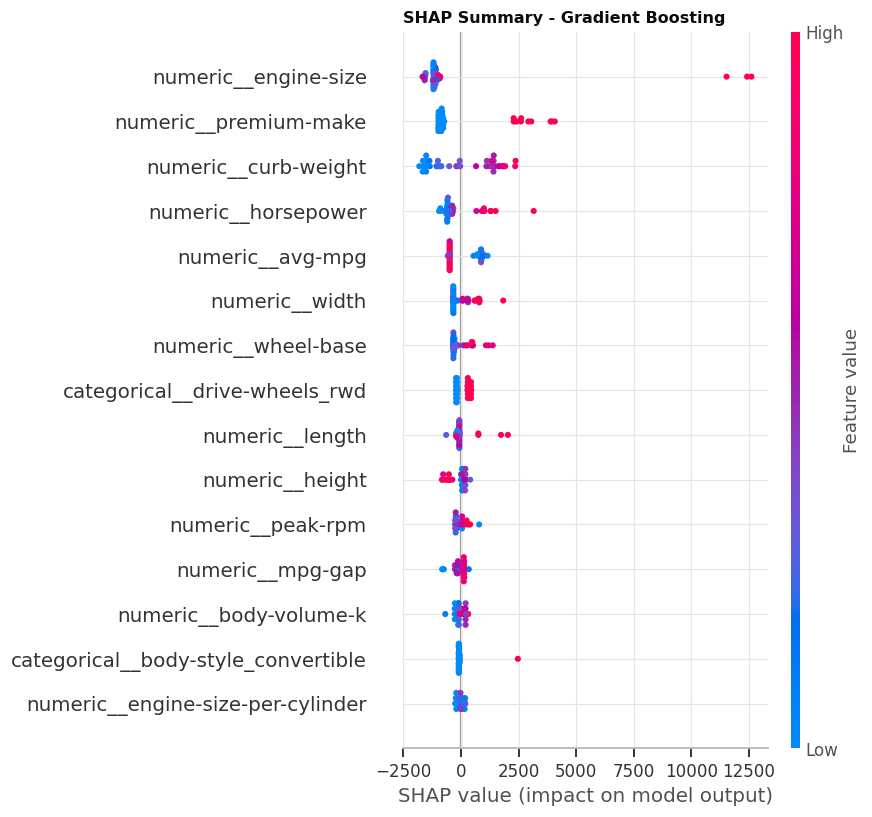

,Feature,Mean_Abs_SHAP
0,numeric__engine-size,"2,012.34"
1,numeric__premium-make,"1,434.44"
2,numeric__curb-weight,"1,300.70"
3,numeric__horsepower,722.92
4,numeric__avg-mpg,671.10
5,numeric__width,413.43
6,numeric__wheel-base,383.89
7,categorical__drive-wheels_rwd,262.59
8,numeric__length,241.54
9,numeric__height,235.54


In [63]:
# SHAP on the fully transformed feature matrix (feature engineering + preprocessing applied first).
shap_importance = None   # stays None unless SHAP completes successfully

try:
    import shap

    fitted_estimator = best_model.named_steps["model"]
    fitted_preprocessor = best_model.named_steps["preprocess"]

    # Steps 1 + 2 of the fitted pipeline: feature engineering, then preprocessing.
    X_test_transformed = best_model[:-1].transform(X_test)
    transformed_feature_names = list(fitted_preprocessor.get_feature_names_out())

    assert X_test_transformed.shape[1] == len(transformed_feature_names), (
        f"{X_test_transformed.shape[1]} transformed columns but {len(transformed_feature_names)} names"
    )
    X_test_shap = pd.DataFrame(
        np.asarray(X_test_transformed, dtype=float),
        columns=transformed_feature_names,
        index=X_test.index,
    )

    tree_estimator_types = (
        DecisionTreeRegressor, RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
    )
    is_tree_compatible = (
        isinstance(fitted_estimator, tree_estimator_types)
        or type(fitted_estimator).__name__ in ("XGBRegressor", "LGBMRegressor")
    )

    if is_tree_compatible:
        explainer_used = "TreeExplainer"
        explainer = shap.TreeExplainer(fitted_estimator)
        shap_values = np.asarray(explainer.shap_values(X_test_shap))
    else:
        explainer_used = "model-agnostic Explainer"
        background = pd.DataFrame(
            np.asarray(best_model[:-1].transform(X_train), dtype=float),
            columns=transformed_feature_names,
        ).sample(n=min(50, len(X_train)), random_state=RANDOM_STATE)
        explainer = shap.Explainer(fitted_estimator.predict, background)
        shap_values = np.asarray(explainer(X_test_shap).values)

    assert shap_values.shape == X_test_shap.shape, (
        f"SHAP values {shap_values.shape} do not match the feature matrix {X_test_shap.shape}"
    )
    print(f"SHAP computed with {explainer_used} for {type(fitted_estimator).__name__} "
          f"on {X_test_shap.shape[0]} test cars x {X_test_shap.shape[1]} transformed features.")

    shap.summary_plot(shap_values, X_test_shap, max_display=15, show=False)
    plt.title(f"SHAP Summary - {best_model_name}")
    plt.tight_layout()
    plt.show()

    shap_importance = (
        pd.DataFrame({
            "Feature": transformed_feature_names,
            "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0),
        })
        .sort_values("Mean_Abs_SHAP", ascending=False)
        .reset_index(drop=True)
    )
    display(shap_importance.head(15))

except ImportError:
    plt.close("all")
    print("SHAP was skipped: the 'shap' library is not installed (pip install shap).")
    print("Permutation importance above is used as the alternative explainability method.")

except Exception as e:
    plt.close("all")
    print("SHAP could not be generated.")
    print("Reason:", type(e).__name__, "-", str(e))
    print("Permutation importance above is used as the alternative explainability method.")


In [64]:
print("BUSINESS RECOMMENDATIONS")

print("\n1. Car Dealers")
print(
    "Use predicted prices as decision-support estimates "
    "when reviewing vehicle inventory and pricing."
)

print("\n2. Car Importers")
print(
    "Compare specifications and predicted prices "
    "before evaluating potential imports."
)

print("\n3. Pricing Teams")
print(
    "Monitor prediction errors and review vehicles "
    "with unusually large differences between actual "
    "and predicted prices."
)

print("\n4. Model Improvement")
print(
    "Collect larger and more recent vehicle-market data "
    "before using this model for real commercial pricing."
)

print("\nTop observed predictors:")
display(feature_importance.head(10))

BUSINESS RECOMMENDATIONS

1. Car Dealers
Use predicted prices as decision-support estimates when reviewing vehicle inventory and pricing.

2. Car Importers
Compare specifications and predicted prices before evaluating potential imports.

3. Pricing Teams
Monitor prediction errors and review vehicles with unusually large differences between actual and predicted prices.

4. Model Improvement
Collect larger and more recent vehicle-market data before using this model for real commercial pricing.

Top observed predictors:


,Feature,Importance_Mean,Importance_Std
16,engine-size,"1,317.87",232.67
13,curb-weight,894.60,158.83
2,make,651.58,152.69
21,horsepower,238.01,69.08
9,wheel-base,235.89,78.54
11,width,96.28,81.03
12,height,81.61,61.80
22,peak-rpm,73.64,36.27
24,highway-mpg,68.52,74.01
7,drive-wheels,49.62,39.23


In [65]:
challenge_report = pd.DataFrame([
    {
        "Challenge": "Missing values represented by '?'",
        "Identification": "Data quality and missing-value analysis",
        "Solution": "Convert '?' to NaN and apply pipeline imputation",
        "Reason": "Retain useful observations without imputing the target",
        "Impact": "Allows models to process incomplete predictor values"
    },
    {
        "Challenge": "Mixed numerical and categorical variables",
        "Identification": "Dataset data-type inspection",
        "Solution": "ColumnTransformer with separate preprocessing pipelines",
        "Reason": "Different data types require different transformations",
        "Impact": "Consistent preprocessing for all models"
    },
    {
        "Challenge": "Different feature scales",
        "Identification": "Numerical feature distribution analysis",
        "Solution": "Apply scaling where appropriate",
        "Reason": "Prevents large-scale features from dominating scale-sensitive models",
        "Impact": "Improves suitability of preprocessing for linear and distance-based models"
    },
    {
        "Challenge": "Identical specifications with different recorded prices",
        "Identification": "Group rows by all predictor columns and compare target-price values",
        "Solution": "Report conflicting groups and retain them for modelling",
        "Reason": "The supplied attributes do not explain the price difference; deleting records without evidence could remove valid observations",
        "Impact": "Creates an irreducible uncertainty for cars with identical recorded specifications"
    },
    {
        "Challenge": "Model overfitting",
        "Identification": "Compare training and cross-validation metrics",
        "Solution": "Cross-validation and hyperparameter tuning",
        "Reason": "Evaluate generalization and control model complexity",
        "Impact": "Supports more reliable model selection"
    },
    {
        "Challenge": "Model interpretability",
        "Identification": "Review prediction drivers",
        "Solution": "Permutation importance and optional SHAP",
        "Reason": "Understand which input features affect model predictions",
        "Impact": "Provides interpretable model insights"
    },
    {
        "Challenge": "Small historical dataset",
        "Identification": "Dataset source and row-count inspection",
        "Solution": "Use cross-validation and clearly document limitations",
        "Reason": "A small historical sample may not represent current markets",
        "Impact": "Prevents overclaiming commercial accuracy"
    }
])

display(challenge_report)

,Challenge,Identification,Solution,Reason,Impact
0,Missing values represented by '?',Data quality and missing-value analysis,Convert '?' to NaN and apply pipeline imputation,Retain useful observations without imputing th...,Allows models to process incomplete predictor ...
1,Mixed numerical and categorical variables,Dataset data-type inspection,ColumnTransformer with separate preprocessing ...,Different data types require different transfo...,Consistent preprocessing for all models
2,Different feature scales,Numerical feature distribution analysis,Apply scaling where appropriate,Prevents large-scale features from dominating ...,Improves suitability of preprocessing for line...
3,Identical specifications with different record...,Group rows by all predictor columns and compar...,Report conflicting groups and retain them for ...,The supplied attributes do not explain the pri...,Creates an irreducible uncertainty for cars wi...
4,Model overfitting,Compare training and cross-validation metrics,Cross-validation and hyperparameter tuning,Evaluate generalization and control model comp...,Supports more reliable model selection
5,Model interpretability,Review prediction drivers,Permutation importance and optional SHAP,Understand which input features affect model p...,Provides interpretable model insights
6,Small historical dataset,Dataset source and row-count inspection,Use cross-validation and clearly document limi...,A small historical sample may not represent cu...,Prevents overclaiming commercial accuracy


## 17. Production Model, Saving and Final Conclusion

In [66]:
from pathlib import Path
import json
import joblib

# Same project root as the rest of the notebook (works from the project root or from notebooks/).
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Artifact directory:", ARTIFACT_DIR.resolve())

Artifact directory: /content/artifacts


In [67]:
MODEL_PATH = ARTIFACT_DIR / "auto_price_model.joblib"

# Save the COMPLETE fitted pipeline (feature engineering + preprocessing + model), not just the estimator.
assert list(best_model.named_steps) == ["engineer", "preprocess", "model"]

joblib.dump(
    best_model,
    MODEL_PATH
)

# Prove the saved file is usable: reload it and compare its predictions with the in-memory model.
reloaded_model = joblib.load(MODEL_PATH)
assert np.allclose(reloaded_model.predict(X_test), best_pred), "Reloaded model predictions differ"

print(f"Model saved: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:,.1f} KB)")
print("Reloaded pipeline reproduces the test predictions.")
print("Note: the pipeline refers to engineer_features by name, so a separate script that loads this file "
      "must define the same engineer_features function (Section 10) before calling joblib.load.")

Model saved: /content/artifacts/auto_price_model.joblib (155.6 KB)
Reloaded pipeline reproduces the test predictions.
Note: the pipeline refers to engineer_features by name, so a separate script that loads this file must define the same engineer_features function (Section 10) before calling joblib.load.


In [68]:
# Raw input columns the pipeline was trained on (BEFORE feature engineering).
raw_feature_columns = X_train.columns.tolist()
raw_numeric_columns = [c for c in raw_feature_columns if c in numeric_predictors]
raw_categorical_columns = [c for c in raw_feature_columns if c not in raw_numeric_columns]


def predict_vehicle_price(specifications, model=None):
    """Predict the price of one vehicle from a dictionary of RAW specifications.

    The fitted pipeline already performs feature engineering, imputation, encoding and scaling,
    so the raw values are passed straight to it - nothing is engineered here.
    Fields left out of the dictionary are treated as missing and imputed by the pipeline.
    """
    model = best_model if model is None else model

    if not isinstance(specifications, dict):
        raise TypeError("specifications must be a Python dictionary")

    unknown_fields = sorted(set(specifications) - set(raw_feature_columns))
    if unknown_fields:
        raise ValueError(f"Unknown vehicle fields: {unknown_fields}. Expected: {raw_feature_columns}")

    # One-row DataFrame with exactly the raw training columns, in the training order.
    input_df = pd.DataFrame([specifications]).reindex(columns=raw_feature_columns)
    input_df[raw_numeric_columns] = input_df[raw_numeric_columns].apply(pd.to_numeric, errors="coerce")
    input_df[raw_categorical_columns] = input_df[raw_categorical_columns].astype(object)

    prediction = model.predict(input_df)[0]

    return round(float(prediction), 2)


print("Prediction function created successfully.")

Prediction function created successfully.


In [69]:
# Test with a real vehicle from the training set.
sample_index = X_train.index[0]
sample_vehicle = X_train.loc[sample_index].to_dict()

predicted_price = predict_vehicle_price(sample_vehicle)

# The helper must agree with calling the fitted pipeline directly on the raw row.
direct_prediction = float(best_model.predict(X_train.loc[[sample_index]])[0])
assert isinstance(predicted_price, float) and np.isfinite(predicted_price)
assert abs(predicted_price - direct_prediction) < 0.01, "Helper and pipeline disagree"

print("Sample vehicle prediction:")
print(f"Predicted price: {predicted_price:,.2f}   (actual price: {y_train.loc[sample_index]:,.2f})")

# A vehicle with a missing optional field is still handled (the pipeline imputes it).
partial_vehicle = {k: v for k, v in sample_vehicle.items() if k != "normalized-losses"}
print(f"Prediction with 'normalized-losses' omitted: {predict_vehicle_price(partial_vehicle):,.2f}")

# Unknown field names are rejected clearly.
try:
    predict_vehicle_price({**sample_vehicle, "colour": "red"})
except ValueError as error:
    print("Unknown field rejected:", error)

Sample vehicle prediction:
Predicted price: 7,910.40   (actual price: 7,463.00)
Prediction with 'normalized-losses' omitted: 7,884.09
Unknown field rejected: Unknown vehicle fields: ['colour']. Expected: ['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg']


In [70]:
def _json_safe(value):
    """Convert NumPy numbers to plain Python numbers (NaN -> None) so the JSON file is valid."""
    if isinstance(value, (np.floating, float)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, np.integer):
        return int(value)
    return value


# Model comparison: original cross-validation results.
cv_results.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)

# Combined training + cross-validation comparison (Section 14.1).
combined_comparison.to_csv(ARTIFACT_DIR / "combined_model_comparison.csv", index=False)

# Tuning results.
tuned_comparison.to_csv(ARTIFACT_DIR / "tuned_model_comparison.csv", index=False)

# Actual and predicted test prices.
predictions_df = pd.DataFrame({
    "Actual_Price": np.asarray(y_test),
    "Predicted_Price": best_pred,
    "Prediction_Error": np.asarray(y_test) - best_pred,
    "Absolute_Error": np.abs(
        np.asarray(y_test) - best_pred
    )
})
predictions_df.to_csv(ARTIFACT_DIR / "predictions.csv", index=False)

# Permutation feature importance.
feature_importance.to_csv(ARTIFACT_DIR / "feature_importance.csv", index=False)

# SHAP importance only exists if SHAP ran successfully.
if shap_importance is not None:
    shap_importance.to_csv(ARTIFACT_DIR / "shap_importance.csv", index=False)

# Final evaluation metrics.
with open(ARTIFACT_DIR / "final_metrics.json", "w") as file:
    json.dump({k: _json_safe(v) for k, v in final_metrics.items()}, file, indent=4)

# Challenges report.
challenge_report.to_csv(ARTIFACT_DIR / "challenges_report.csv", index=False)

print("Save commands finished. Check the verification table below for the files that actually exist.")

Save commands finished. Check the verification table below for the files that actually exist.


In [71]:
# Verify that every expected artifact really exists on disk.
expected_files = [
    "auto_price_model.joblib",
    "model_comparison.csv",
    "combined_model_comparison.csv",
    "tuned_model_comparison.csv",
    "predictions.csv",
    "feature_importance.csv",
    "final_metrics.json",
    "challenges_report.csv",
]
optional_files = ["shap_importance.csv"]   # only created when SHAP ran successfully

rows = []
for filename in expected_files + optional_files:
    path = ARTIFACT_DIR / filename
    rows.append({
        "File": filename,
        "Required": filename in expected_files,
        "Exists": path.exists() and path.stat().st_size > 0,   # an empty file does not count
        "Size_KB": round(path.stat().st_size / 1024, 2) if path.exists() else None,
    })
artifact_check = pd.DataFrame(rows)
display(artifact_check)

missing_required = [r["File"] for r in rows if r["Required"] and not r["Exists"]]

# The saved model must also load again and reproduce the test predictions.
try:
    assert np.allclose(joblib.load(ARTIFACT_DIR / "auto_price_model.joblib").predict(X_test), best_pred)
    print("Saved model reloads and reproduces the test predictions.")
except Exception as error:
    missing_required.append(f"auto_price_model.joblib (cannot be reloaded: {type(error).__name__})")

if missing_required:
    print("MISSING required artifacts:", missing_required)
else:
    print(f"All {len(expected_files)} required artifact files exist in {ARTIFACT_DIR.resolve()}")

,File,Required,Exists,Size_KB
0,auto_price_model.joblib,True,True,155.59
1,model_comparison.csv,True,True,1.49
2,combined_model_comparison.csv,True,True,2.88
3,tuned_model_comparison.csv,True,True,0.24
4,predictions.csv,True,True,2.51
5,feature_importance.csv,True,True,1.15
6,final_metrics.json,True,True,0.25
7,challenges_report.csv,True,True,1.70
8,shap_importance.csv,False,True,3.07


Saved model reloads and reproduces the test predictions.
All 8 required artifact files exist in /content/artifacts


# Final Project Conclusion

## Business Problem

The project focuses on predicting automobile prices using vehicle specifications and machine learning regression algorithms.

## Dataset

The project uses the historical Automobile Imports dataset, containing vehicle specifications and automobile prices.

## Data Cleaning

Missing values were identified and handled through preprocessing pipelines. Numerical and categorical features were processed separately.

## Exploratory Data Analysis

Numerical distributions, categorical attributes, price relationships, correlations and potential outliers were investigated.

## Feature Engineering

Additional features were created to represent vehicle dimensions, fuel efficiency and engine characteristics.

## Machine Learning Models

Multiple regression algorithms were trained and compared.

## Model Selection

The final model was selected using training cross-validation MAE rather than test-set performance.

## Final Evaluation

The selected model was evaluated using the untouched test dataset. Adjusted R² is intentionally not reported because it is not a valid measure for a nonlinear ensemble (see Section 16).

Record the actual MAE, RMSE, R² and other evaluation metrics from the executed notebook.

## Explainable AI

Permutation feature importance was used to understand which vehicle specifications contributed most to model predictions. SHAP values were calculated on the fully transformed feature matrix when the `shap` library was installed and compatible with the selected model; otherwise the notebook reports that SHAP was skipped.

## Business Recommendations

The model can support preliminary price estimation, inventory review and pricing analysis. It should not be treated as a current-market valuation system without updated data.

## Limitations

- The dataset is relatively small.
- The data is historical.
- The model may not generalize to current automobile markets.
- Seven repeated predictor groups in the supplied file have different recorded prices; the model cannot distinguish those price differences from the available inputs.
- Predictions depend on the quality and range of input specifications.

## Future Improvements

- Collect larger and more recent automobile datasets.
- Evaluate additional regression and ensemble algorithms.
- Improve model calibration and generalization.
- Deploy the model through a prediction API.
- Monitor prediction errors using new market data.